# TP - Regularización en el MLP de 20 Newsgroups
### Redes Neuronales / Deep Learning

Continuación del TP de **Clasificación de 20 Newsgroups con MLP**: mismo dataset, preprocesamiento de texto y split. Cambia la entrada: `min_df = 5` y TF-IDF **estandarizado por palabra** (sección 1).

## Consigna
En base a las recomendaciones vistas durante las clases de regularización, incluir como hiperparámetros posibles en el trabajo práctico de Clasificación de TNG los siguientes elementos:
- Regularización L1/L2, L1+L2
- Dropout
- BatchNormalization

Para cada caso tener en cuenta las recomendaciones de clase. Mirar valores absolutos de pesos. Tiempos de entrenamiento. Valores de Learning Rate. Ruido en las curvas de aprendizaje. Justificar con lo visto en clase los fenómenos observados.

## Organización
1. Datos, modelo y entrenamiento (secciones 1 a 3).
2. **Pruebas manuales**: una técnica por vez sobre una red sobredimensionada (secciones 4 a 8).
3. **Búsqueda con Optuna** con las tres técnicas como hiperparámetros (sección 9).
4. Entrenamiento final y test (sección 10), conclusiones (sección 11) y entorno (sección 12).

## 0. Setup

In [1]:
!pip install -q mlflow==3.18.0 optuna==5.0.0

In [2]:
import os
import time
import pickle
import random
import logging
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

import mlflow
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

for logger_name in ["mlflow", "alembic"]:
    logging.getLogger(logger_name).setLevel(logging.ERROR)
optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri("sqlite:///mlflow.db")   # los runs quedan en ./mlflow.db (se entrega junto con la notebook)
mlflow.set_experiment("mlp_20newsgroups_regularizacion")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device, "| hilos de CPU:", torch.get_num_threads())
print("torch", torch.__version__, "| optuna", optuna.__version__, "| mlflow", mlflow.__version__)

Usando dispositivo: cuda | hilos de CPU: 1
torch 2.14.1+cu130 | optuna 5.0.0 | mlflow 3.18.0


## 1. Datos y preprocesamiento

Se reutiliza el pipeline del TP anterior: sin stopwords, sin stemming ni lematización, unigramas y `max_features = 20000`. El split train/val es el mismo (80/20 estratificado, `random_state = 42`) y el test oficial *bydate* solo se usa al final.

Cambios:
- **Estandarización por palabra.** Después del TF-IDF, cada palabra se lleva a media 0 y desvío 1 con un `StandardScaler` ajustado solo con train (`featurize`). Se usa `min_df = 5`.


In [3]:
for pkg in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)

STOP_WORDS = set(stopwords.words("english"))


def preprocess_text(text):
    tokens = word_tokenize(text.lower())
    return " ".join(t for t in tokens if t.isalpha() and t not in STOP_WORDS)


CACHE_PATH = "preprocessed_cache_reg.pkl"
if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, "rb") as f:
        train_texts, test_texts = pickle.load(f)
else:
    train_texts = [preprocess_text(t) for t in newsgroups_train.data]
    test_texts = [preprocess_text(t) for t in newsgroups_test.data]
    with open(CACHE_PATH, "wb") as f:
        pickle.dump((train_texts, test_texts), f)

y_full = np.asarray(newsgroups_train.target)
idx_tr, idx_val = train_test_split(np.arange(len(y_full)), test_size=0.2, random_state=SEED, stratify=y_full)
tr_texts = [train_texts[i] for i in idx_tr]
val_texts = [train_texts[i] for i in idx_val]


def featurize(fit_texts, other_texts, min_df):
    """TF-IDF + estandarización por feature (media 0, desvío 1).
    El vectorizador y el StandardScaler se ajustan SOLO con fit_texts y se aplican a other_texts."""
    vec = TfidfVectorizer(ngram_range=(1, 1), max_features=20000, min_df=min_df)
    S_fit = vec.fit_transform(fit_texts)
    scaler = StandardScaler().fit(S_fit.toarray().astype(np.float32))
    to_z = lambda S: scaler.transform(S.toarray().astype(np.float32))
    return S_fit, to_z(S_fit), to_z(vec.transform(other_texts))


def to_device(X, y):
    return (torch.tensor(X, dtype=torch.float32, device=device),
            torch.tensor(np.asarray(y), dtype=torch.long, device=device))


MIN_DF = 5
S_tr, X_tr, X_val = featurize(tr_texts, val_texts, MIN_DF)
DATA = (*to_device(X_tr, y_full[idx_tr]), *to_device(X_val, y_full[idx_val]))   # (X_tr, y_tr, X_val, y_val)
INPUT_DIM = X_tr.shape[1]
print(f"Train: {len(idx_tr)} | Val: {len(idx_val)} | Test: {len(test_texts)} | palabras (min_df = {MIN_DF}): {INPUT_DIM}")
print(f"Entrada estandarizada -> desvío en train {X_tr.std():.3f}, en val {X_val.std():.3f} | máximo en train {X_tr.max():.1f} "
      f"| docs de train sin palabras: {int((S_tr.getnnz(axis=1) == 0).sum())}")

Train: 9051 | Val: 2263 | Test: 7532 | palabras (min_df = 5): 13148
Entrada estandarizada -> desvío en train 1.000, en val 1.188 | máximo en train 95.1 | docs de train sin palabras: 261


### Estandarización y palabras raras

**Por qué se estandariza.** Como se recomendó en clase, todas las features quedan con la misma escala (media 0, desvío 1). Es la condición para usar un $\lambda$ único en L1 y L2, y la primera capa recibe entradas centradas.

**Cómo afectan las palabras raras.** Una palabra que aparece en $k$ de los $n$ = 9051 documentos de train tiene media cercana a 0 y un desvío chico, del orden de $\sqrt{k/n}$ veces su TF-IDF. Al estandarizar, en los documentos donde aparece queda en $z \approx \sqrt{n/k}$: cuanto más rara la palabra, más grande el valor con el que entra a la red. En documentos cortos, o donde la palabra se repite, queda todavía más arriba: el máximo en train es 95.1. Consecuencias:
- **Train y validación quedan desalineados.** La entrada de validación tiene desvío 1.188 (en train, 1.000): palabras que en train aparecen en pocos documentos aparecen más en validación, con valores que el modelo no vio.
- **La red memoriza en una época** (sección 4) y **el learning rate estable es bajo** (sección 8).
- Los 261 documentos de train que quedan sin palabras (al sacar headers, footers y citas) se convierten todos en el mismo vector $-\mu/\sigma$.

**`min_df = 5`.** Exigir que cada palabra aparezca en al menos 5 documentos acota ese valor típico en $\sqrt{n/5} \approx 42.5$.

## 2. Modelo: MLP con regularización

Es el MLP del TP anterior con las tres técnicas como opciones. Cada una se implementa siguiendo lo visto en clase:

| Técnica | Recomendación de clase | En el código |
|---|---|---|
| **L2 (Ridge)** | Se suma $\lambda\sum w^2$ a la entropía cruzada. $\lambda$ se busca en escala logarítmica. Se aplica por capa, a los pesos `w` y no a los bias. | `reg_penalty`: `l2 * w.pow(2).sum()` sobre el `weight` de cada `nn.Linear` |
| **L1 (Lasso)** | Se suma $\lambda\sum \lvert w\rvert$: todos los pesos se reducen por igual, lo que da pesos esparsos (selección de parámetros). Se puede combinar con L2. | `reg_penalty`: `l1 * w.abs().sum()`. L1+L2 usa los dos términos |
| **Dropout** | Rate bajo (20–50%), red grande, en cada capa oculta y eventualmente en la entrada; no en la salida. Learning rate más alto con decay. Max-norm de 4 o 5. Necesita más épocas. | `nn.Dropout(p)` después de cada activación oculta, `input_dropout` en la entrada, `max_norm` y `ReduceLROnPlateau` en el entrenamiento |
| **Batch Normalization** | `Dense(use_bias=False) → BN → activación`. No combinar con dropout. Permite subir el learning rate. El momentum es configurable. | `nn.Linear(bias=False) → nn.BatchNorm1d → activación` |


In [4]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu",
                 dropout=0.0, input_dropout=0.0, batchnorm=False, bn_momentum=0.1):
        super().__init__()
        layers, d = [], input_dim
        if input_dropout > 0:
            layers.append(nn.Dropout(input_dropout))
        for h in hidden_sizes:
            layers.append(nn.Linear(d, h, bias=not batchnorm))   # con BN el bias es redundante (lo hace beta)
            if batchnorm:
                layers.append(nn.BatchNorm1d(h, momentum=bn_momentum))
            layers.append(ACTIVATIONS[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, num_classes))   # capa de salida: logits, sin dropout ni BN
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def build_model(cfg, input_dim=None):
    return MLP(input_dim or INPUT_DIM, cfg["hidden"], NUM_CLASSES, cfg.get("activation", "relu"),
               dropout=cfg.get("dropout", 0.0), input_dropout=cfg.get("input_dropout", 0.0),
               batchnorm=cfg.get("batchnorm", False), bn_momentum=cfg.get("bn_momentum", 0.1)).to(device)


def kernels(model):
    # Matrices de pesos w de las capas densas (sin bias ni parámetros de BN)
    return [m.weight for m in model.modules() if isinstance(m, nn.Linear)]


def reg_penalty(model, l1=0.0, l2=0.0):
    pen = 0.0
    for w in kernels(model):
        if l1 > 0:
            pen = pen + l1 * w.abs().sum()
        if l2 > 0:
            pen = pen + l2 * w.pow(2).sum()
    return pen


@torch.no_grad()
def apply_max_norm(model, max_norm):
    # Si la norma del vector de pesos de entrada de una neurona supera max_norm, se lo reescala a max_norm
    for w in kernels(model):
        w.copy_(torch.renorm(w, p=2, dim=0, maxnorm=max_norm))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


# Ejemplo: la red base con BN
_m = build_model(dict(hidden=[512, 512], batchnorm=True))
print(_m.net)
print("Parámetros:", f"{count_params(_m):,}")
del _m

Sequential(
  (0): Linear(in_features=13148, out_features=512, bias=False)
  (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=512, bias=False)
  (4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): Linear(in_features=512, out_features=20, bias=True)
)
Parámetros: 7,006,228


**Explicación del código.**
- `MLP` arma por cada capa oculta el bloque `Linear → (BatchNorm) → activación → (Dropout)`. Con BN, el `Linear` va sin bias porque el $\beta$ de BN cumple ese rol.
- `reg_penalty` es el término que se suma a la función de costo. Recorre solo las matrices `weight` de las capas densas: los bias y los $\gamma, \beta$ de BN no se regularizan.
- `apply_max_norm` es el *constraint* `max_norm` de Keras: cada fila de `weight` es el vector de pesos de entrada de una neurona, y `torch.renorm` reescala las filas cuya norma supera el máximo. Cambia el módulo del vector, no su dirección.

## 3. Entrenamiento

Es el loop del TP anterior (con early stopping y pruning de Optuna) más lo necesario para regularizar y para medir lo que pide la consigna:

- **Costo regularizado**: se hace backprop de `entropía cruzada + reg_penalty`. En las curvas se reporta solo la entropía cruzada, para que las losses sean comparables entre experimentos.
- **Max-norm** después de cada paso del optimizador y **ReduceLROnPlateau** opcional (monitorea la val acc).
- **Dos mediciones de train**: `train_acc` es el promedio sobre los mini-batches *mientras se entrena* (con dropout activo y BN con las estadísticas del batch); `train_acc_eval` (opcional) evalúa el train al final de la época en modo `eval`, igual que validación.
- **Ruido** (accuracy de cada mini-batch), **pesos** ($\lvert w\rvert$ medio de la primera capa por época) y **tiempo** (`epoch_time`, solo la pasada de entrenamiento). Todo se corrió en la GPU T4 de Colab: con épocas de menos de medio segundo, los tiempos se comparan en términos relativos.

In [5]:
@torch.no_grad()
def evaluate(model, X, y, batch_size=2048):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(y), batch_size):
        logits = model(X[i:i + batch_size])
        loss += nn.functional.cross_entropy(logits, y[i:i + batch_size], reduction="sum").item()
        correct += (logits.argmax(dim=1) == y[i:i + batch_size]).sum().item()
    return loss / len(y), correct / len(y)


def train_model(model, data, optimizer, cfg, trial=None, patience=None, verbose=False, run_name="mlp"):
    X_tr, y_tr, X_val, y_val = data
    n, batch_size = len(y_tr), cfg["batch_size"]
    l1, l2, max_norm = cfg.get("l1", 0.0), cfg.get("l2", 0.0), cfg.get("max_norm")
    scheduler = None
    if cfg.get("plateau"):
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", **cfg["plateau"])
    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "train_loss_eval", "train_acc_eval",
                               "epoch_time", "lr", "batch_acc", "w_abs"]}
    history.update(pruned=False, best_epoch=0, best_val_acc=0.0)
    log_mlflow = mlflow.active_run() is not None
    wait = 0

    for epoch in range(cfg["epochs"]):
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(n, device=y_tr.device)
        running_loss, correct, total, batch_acc = 0.0, 0, 0, []
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:   # BN no admite batches de 1 en entrenamiento
                continue
            xb, yb = X_tr[idx], y_tr[idx]
            optimizer.zero_grad()
            logits = model(xb)
            ce = nn.functional.cross_entropy(logits, yb)
            loss = ce + reg_penalty(model, l1, l2)
            loss.backward()
            optimizer.step()
            if max_norm:
                apply_max_norm(model, max_norm)
            hits = (logits.argmax(dim=1) == yb).sum().item()
            running_loss += ce.item() * len(idx)
            correct += hits
            total += len(idx)
            batch_acc.append(hits / len(idx))
        epoch_time = time.perf_counter() - t0
        train_loss, train_acc = running_loss / total, correct / total
        val_loss, val_acc = evaluate(model, X_val, y_val)

        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc", "epoch_time", "lr", "batch_acc", "w_abs"],
                        [train_loss, train_acc, val_loss, val_acc, epoch_time, optimizer.param_groups[0]["lr"],
                         batch_acc, kernels(model)[0].abs().mean().item()]):
            history[k].append(v)
        if cfg.get("eval_train"):
            tl, ta = evaluate(model, X_tr, y_tr)
            history["train_loss_eval"].append(tl)
            history["train_acc_eval"].append(ta)
        if val_acc > history["best_val_acc"]:
            history["best_val_acc"], history["best_epoch"], wait = val_acc, epoch + 1, 0
        else:
            wait += 1

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{cfg['epochs']} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f}"
                  f" - val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - lr: {history['lr'][-1]:.1e} ({epoch_time:.1f} s)")
        if log_mlflow:
            mlflow.log_metrics({"train_loss": train_loss, "val_loss": val_loss, "train_acc": train_acc,
                                "val_acc": val_acc, "lr": history["lr"][-1]}, step=epoch)
        if scheduler is not None:
            scheduler.step(val_acc)
        if trial is not None:
            trial.report(history["best_val_acc"], epoch)
            if trial.should_prune():
                history["pruned"] = True
                break
        if patience is not None and wait >= patience:
            break

    return history

### 3.1 Experimentos y métricas

Todas las pruebas manuales parten de la misma red **sobredimensionada**: 2 capas ocultas de 512 (`relu`), Adam con `lr = 1e-3`, `batch_size = 128` y 20 épocas sin early stopping. Es la red `2x512` que en el TP anterior ya sobreajustaba, y sigue la recomendación de clase de regularizar sobre una red grande: tiene 7.0 M de parámetros para 9051 documentos. Cada prueba cambia **una cosa** respecto de esa base, con la misma semilla.

| Consigna | Qué se mide |
|---|---|
| Performance | Máximo de val acc y su época, val acc final, val loss mínima y final, *gap* train − val |
| **Pesos** | Por capa: $\lvert w\rvert$ medio y máximo, norma media del vector de pesos de cada neurona y % de pesos con $\lvert w\rvert < 10^{-3}$. En la capa 1, neuronas apagadas (norma < 0.1), histogramas y $\lvert w\rvert$ medio por época |
| **Tiempos** | Segundos por época (mediana) y época de convergencia (primera a 1 pp del máximo de val acc) |
| **Ruido** | *Train*: desvío de la accuracy por mini-batch en las últimas 5 épocas. *Val*: variación media de la val acc entre épocas en las últimas 10. En puntos porcentuales (pp) |

Cada corrida queda registrada en MLflow.

In [6]:
BASE = dict(hidden=[512, 512], activation="relu", lr=1e-3, batch_size=128, epochs=20)
results, models = {}, {}


@torch.no_grad()
def weight_stats(model, thr=1e-3):
    ws, out = kernels(model), {}
    for i, w in enumerate(ws):
        tag = f"capa {i+1}" if i < len(ws) - 1 else "salida"
        a = w.abs()
        out[f"|w| medio ({tag})"] = a.mean().item()
        out[f"|w| máx ({tag})"] = a.max().item()
        out[f"norma/neurona ({tag})"] = w.norm(dim=1).mean().item()
        out[f"% |w|<1e-3 ({tag})"] = 100 * (a < thr).float().mean().item()
    gammas = [m.weight.abs().mean().item() for m in model.modules() if isinstance(m, nn.BatchNorm1d)]
    if gammas:
        out["gamma medio (BN)"] = float(np.mean(gammas))
    return out


def run_experiment(name, keep=False, **kw):
    cfg = {**BASE, **kw}
    torch.manual_seed(SEED)
    model = build_model(cfg)
    optimizer = optim.Adam(model.parameters(), lr=cfg["lr"])
    with mlflow.start_run(run_name=name):
        mlflow.log_params({k: str(v) for k, v in cfg.items()})
        h = train_model(model, DATA, optimizer, cfg, run_name=name)
        h["cfg"], h["w"] = cfg, weight_stats(model)
        norms1 = kernels(model)[0].detach().norm(dim=1)
        h["w"]["n neuronas norma < 0.1 (capa 1)"] = int((norms1 < 0.1).sum())
        mlflow.log_metrics({"train_time_s": sum(h["epoch_time"]), "best_val_acc": h["best_val_acc"],
                            "w_abs_capa1": h["w"]["|w| medio (capa 1)"]})
    w1 = kernels(model)[0].detach()
    h["w1_sample"] = w1.flatten()[torch.randperm(w1.numel(), device=w1.device)[:300_000]].cpu().numpy()
    h["neuron_norms"] = w1.norm(dim=1).cpu().numpy()
    results[name] = h
    if keep:
        models[name] = model
    print(f"{name:42s} máx val_acc {h['best_val_acc']:.4f} (ép. {h['best_epoch']:2d}) | final {h['val_acc'][-1]:.4f} "
          f"| train {h['train_acc'][-1]:.4f} | val_loss final {h['val_loss'][-1]:.3f} | {np.median(h['epoch_time']):.2f} s/época")
    return h


def conv_epoch(h, tol=0.01):
    va = np.array(h["val_acc"])
    return int(np.argmax(va >= va.max() - tol)) + 1


def ruido_train(h, last=5):
    return 100 * np.sqrt(np.mean([np.var(b) for b in h["batch_acc"][-last:]]))


def ruido_val(h, last=10):
    return 100 * np.mean(np.abs(np.diff(h["val_acc"][-last:])))


def resumen(names):
    rows = {}
    for name in names:
        h = results[name]
        va, ec = np.array(h["val_acc"]), conv_epoch(h)
        rows[name] = {
            "máx val_acc": va.max(), "ép. máx": va.argmax() + 1, "val_acc final": va[-1],
            "train_acc final": h["train_acc"][-1], "gap final": h["train_acc"][-1] - va[-1],
            "val_loss mín": min(h["val_loss"]), "val_loss final": h["val_loss"][-1],
            "ruido train [pp]": ruido_train(h), "ruido val [pp]": ruido_val(h),
            "s/época": np.median(h["epoch_time"]), "ép. conv.": ec,
        }
    fmt = {c: "{:.4f}" for c in ["máx val_acc", "val_acc final", "train_acc final", "gap final"]}
    fmt |= {c: "{:.3f}" for c in ["val_loss mín", "val_loss final"]} | {c: "{:.0f}" for c in ["ép. máx", "ép. conv."]}
    fmt |= {c: "{:.2f}" for c in ["ruido train [pp]", "ruido val [pp]", "s/época"]}
    return pd.DataFrame(rows).T.style.format(fmt)


def resumen_pesos(names):
    df_w = pd.DataFrame({name: results[name]["w"] for name in names}).T
    fmt = {c: ("{:.1f}" if c.startswith("%") else "{:.0f}" if c.startswith("n ") else
               "{:.2f}" if c.startswith("norma") or c.startswith("gamma") else "{:.4f}")
           for c in df_w.columns}
    return df_w.style.format(fmt, na_rep="-")


def plot_curvas(names, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
    for i, name in enumerate(names):
        h, c = results[name], f"C{i}"
        ep = np.arange(1, len(h["val_acc"]) + 1)
        ax[0].plot(ep, h["train_loss"], "--", color=c); ax[0].plot(ep, h["val_loss"], color=c, label=name)
        ax[1].plot(ep, h["train_acc"], "--", color=c); ax[1].plot(ep, h["val_acc"], color=c, label=name)
    ax[0].set(title=f"{title} - loss (-- train, — val)", xlabel="época", yscale="log")
    ax[1].set(title=f"{title} - accuracy (-- train, — val)", xlabel="época", ylim=(0.3, 1.0))
    for a in ax:
        a.legend(fontsize=8)
    plt.tight_layout(); plt.show()


def plot_pesos(names, title):
    fig, ax = plt.subplots(1, 3, figsize=(19, 4.3))
    lim = max(np.abs(results[name]["w1_sample"]).max() for name in names)
    bins = np.linspace(-lim, lim, 151)
    todas = np.concatenate([results[n]["neuron_norms"] for n in names])
    bins_n = np.linspace(todas.min(), todas.max(), 41)
    for i, name in enumerate(names):
        h, c = results[name], f"C{i}"
        ax[0].hist(h["w1_sample"], bins=bins, histtype="step", color=c, label=name)
        ax[1].hist(h["neuron_norms"], bins=bins_n, histtype="step", color=c, label=name)
        ax[2].plot(np.arange(1, len(h["w_abs"]) + 1), h["w_abs"], color=c, label=name)
    ax[0].set(title=f"{title} - histograma de pesos, capa 1", xlabel="w", yscale="log")
    ax[1].set(title="Norma L2 de los pesos de cada neurona, capa 1", xlabel="norma")
    ax[2].set(title="|w| medio de la capa 1 por época", xlabel="época", yscale="log")
    for a in ax:
        a.legend(fontsize=8)
    plt.tight_layout(); plt.show()


def plot_ruido(names, title):
    fig, ax = plt.subplots(1, len(names), figsize=(6.3 * len(names), 4), sharey=True, squeeze=False)
    for a, name in zip(ax[0], names):
        h = results[name]
        epochs = len(h["val_acc"])
        b = np.concatenate(h["batch_acc"])
        a.plot(np.linspace(0, epochs, len(b)), b, lw=0.5, color="C0", label="train, por mini-batch")
        a.plot(np.arange(1, epochs + 1), h["val_acc"], "o-", ms=3, color="C1", label="val, por época")
        if h["train_acc_eval"]:
            a.plot(np.arange(1, epochs + 1), h["train_acc_eval"], ":", color="k", label="train en modo eval, por época")
        a.set(title=f"{name}: ruido train {ruido_train(h):.2f} pp | val {ruido_val(h):.2f} pp", xlabel="época", ylim=(0.3, 1.01))
        a.legend(fontsize=8, loc="lower right")
    plt.suptitle(title); plt.tight_layout(); plt.show()


def curvas(names, n=None):
    # Imprime train acc (con la técnica activa), train acc en modo eval y val acc por época
    for name in names:
        h = results[name]
        k = n or len(h["val_acc"])
        print(f"{name}:")
        print("   train     ", np.round(h["train_acc"][:k], 3).tolist())
        if h["train_acc_eval"]:
            print("   train eval", np.round(h["train_acc_eval"][:k], 3).tolist())
        print("   val       ", np.round(h["val_acc"][:k], 3).tolist())


**Explicación del código.** `run_experiment` entrena una variante de `BASE` con la misma semilla, la registra en MLflow y guarda en `results` el historial y las estadísticas de pesos. `resumen` y `resumen_pesos` arman las tablas; `plot_curvas`, `plot_pesos` y `plot_ruido` los gráficos (en las curvas, punteada = train y continua = val), y `curvas` imprime la accuracy por época.

## 4. Punto de partida: red sobredimensionada sin regularizar

Además de la base, se entrena la misma red con la entrada del TP anterior (TF-IDF con norma L2 por documento, sin estandarizar, `min_df = 2`), para medir el costo de estandarizar.

base                                       máx val_acc 0.7035 (ép.  5) | final 0.6960 | train 0.9732 | val_loss final 1.502 | 0.26 s/época
Parámetros de la red base: 7,005,204
Sin estandarizar (entrada del TP anterior): máx val_acc 0.7243 (ép. 2) | val_loss mín 0.958


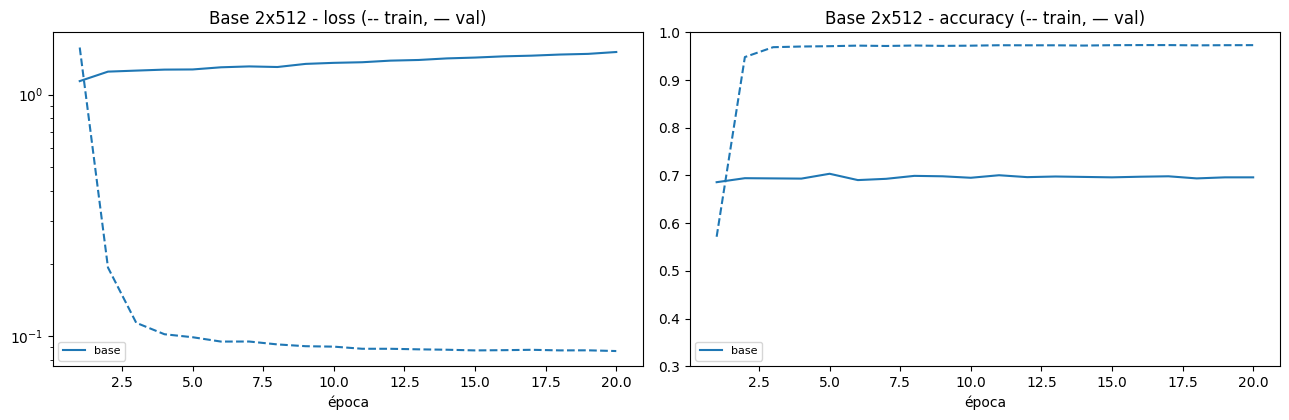

,máx val_acc,ép. máx,val_acc final,train_acc final,gap final,val_loss mín,val_loss final,ruido train [pp],ruido val [pp],s/época,ép. conv.
base,0.7035,5,0.6960,0.9732,0.2772,1.138,1.502,1.41,0.18,0.26,2


,|w| medio (capa 1),|w| máx (capa 1),norma/neurona (capa 1),% |w|<1e-3 (capa 1),|w| medio (capa 2),|w| máx (capa 2),norma/neurona (capa 2),% |w|<1e-3 (capa 2),|w| medio (salida),|w| máx (salida),norma/neurona (salida),% |w|<1e-3 (salida),n neuronas norma < 0.1 (capa 1)
base,0.0090,0.1333,1.29,7.1,0.0249,0.1492,0.67,2.1,0.0270,0.3631,0.73,1.9,0


base:
   train      [0.571, 0.948, 0.969, 0.97, 0.971, 0.972]
   train eval [0.949, 0.97, 0.973, 0.972, 0.973, 0.972]
   val        [0.686, 0.694, 0.694, 0.693, 0.703, 0.69]


In [7]:
run_experiment("base", keep=True, eval_train=True)
print(f"Parámetros de la red base: {count_params(models['base']):,}")

# Referencia: la misma red con la entrada del TP anterior (TF-IDF con norma L2 por documento, sin estandarizar, min_df = 2)
vec_ref = TfidfVectorizer(ngram_range=(1, 1), max_features=20000, min_df=2)
Xr_tr = vec_ref.fit_transform(tr_texts).toarray().astype(np.float32)
Xr_val = vec_ref.transform(val_texts).toarray().astype(np.float32)
torch.manual_seed(SEED)
model = build_model(BASE, input_dim=Xr_tr.shape[1])
h_ref = train_model(model, (*to_device(Xr_tr, y_full[idx_tr]), *to_device(Xr_val, y_full[idx_val])),
                    optim.Adam(model.parameters(), lr=BASE["lr"]), BASE)
print(f"Sin estandarizar (entrada del TP anterior): máx val_acc {max(h_ref['val_acc']):.4f} "
      f"(ép. {int(np.argmax(h_ref['val_acc'])) + 1}) | val_loss mín {min(h_ref['val_loss']):.3f}")
del model, Xr_tr, Xr_val

plot_curvas(["base"], "Base 2x512")
display(resumen(["base"]))
display(resumen_pesos(["base"]))
curvas(["base"], n=6)

### Análisis de la base

- **Sobreajuste rápido.** Medido en modo eval, el train llega a 0.949 en la primera época y a 0.973 (el techo de este train) en la tercera. La val acc tiene su máximo en la época 5 (0.7035) y la val loss sube de 1.138 a 1.502: la red acierta lo mismo, pero cada vez más "segura", también cuando se equivoca.
- **Costo del cambio de entrada.** La misma red con la entrada del TP anterior (sin estandarizar, `min_df = 2`) llega a 0.7243 de val acc y 0.958 de val loss mínima: estandarizar con `min_df = 5` cuesta **2.1 pp**. Se mantiene porque es la recomendación de clase, pero hay que tenerlo en cuenta al comparar con el TP anterior.
- **Pesos.** El $\lvert w\rvert$ medio de la capa 1 termina en 0.0090 (máximo 0.13), apenas el doble de la inicialización ($\frac{1}{2\sqrt{13148}} \approx 0.0044$): con entradas que llegan a decenas, a la red le alcanzan pesos chicos para memorizar.
- **Ruido.** 1.41 pp en train, que es ruido de muestreo: con $p = 0.973$ y batches de 128, $\sqrt{p(1-p)/128} = 1.43$ pp. En val, 0.18 pp.
- **Tiempo.** 0.25 s por época, y converge en 2 épocas.

## 5. Regularización L2, L1 y L1+L2

$\lambda$ se barre en escala logarítmica.

- **L2**: $\lambda \in \{10^{-6}, 10^{-5}, 10^{-4}, 10^{-3}\}$
- **L1**: $\lambda \in \{10^{-7}, 10^{-6}, 10^{-5}, 10^{-4}\}$
- **L1+L2**: $\lambda_1 = 10^{-6}$, $\lambda_2 = 10^{-5}$

In [8]:
grupo_l2 = {f"L2 λ={lam:g}": dict(l2=lam) for lam in [1e-6, 1e-5, 1e-4, 1e-3]}
grupo_l1 = {f"L1 λ={lam:g}": dict(l1=lam) for lam in [1e-7, 1e-6, 1e-5, 1e-4]}
grupo_l1l2 = {"L1+L2 (1e-06, 1e-05)": dict(l1=1e-6, l2=1e-5)}
for name, kw in {**grupo_l2, **grupo_l1, **grupo_l1l2}.items():
    run_experiment(name, keep=name == "L1 λ=1e-06", **kw)

L2 λ=1e-06                                 máx val_acc 0.7008 (ép.  5) | final 0.6938 | train 0.9728 | val_loss final 1.475 | 0.35 s/época
L2 λ=1e-05                                 máx val_acc 0.7013 (ép.  5) | final 0.6911 | train 0.9730 | val_loss final 1.396 | 0.35 s/época
L2 λ=0.0001                                máx val_acc 0.6982 (ép.  3) | final 0.6898 | train 0.9729 | val_loss final 1.197 | 0.35 s/época
L2 λ=0.001                                 máx val_acc 0.7084 (ép.  1) | final 0.5886 | train 0.8980 | val_loss final 2.127 | 0.35 s/época
L1 λ=1e-07                                 máx val_acc 0.7075 (ép. 12) | final 0.6969 | train 0.9729 | val_loss final 1.422 | 0.33 s/época
L1 λ=1e-06                                 máx val_acc 0.7044 (ép.  5) | final 0.6986 | train 0.9729 | val_loss final 1.279 | 0.33 s/época
L1 λ=1e-05                                 máx val_acc 0.7004 (ép.  5) | final 0.6460 | train 0.9732 | val_loss final 1.889 | 0.33 s/época
L1 λ=0.0001                

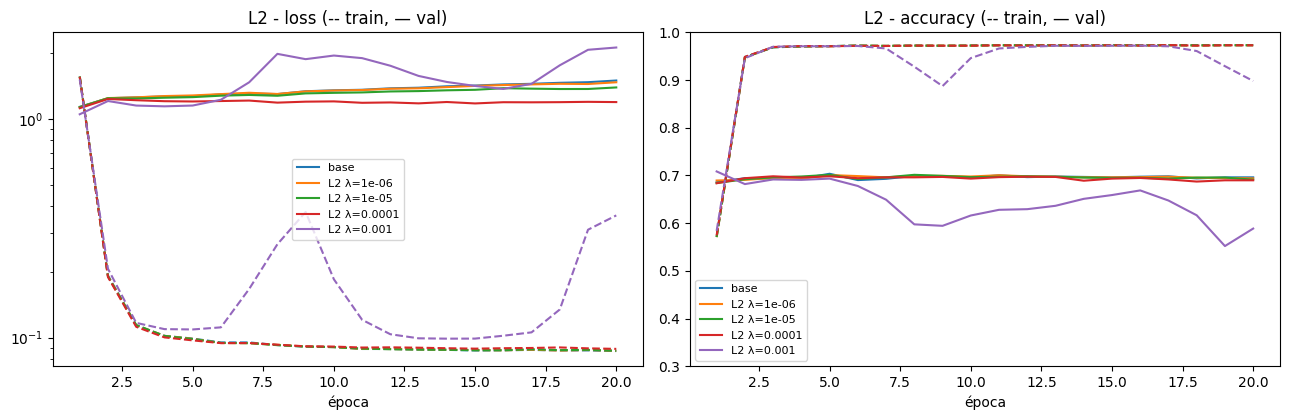

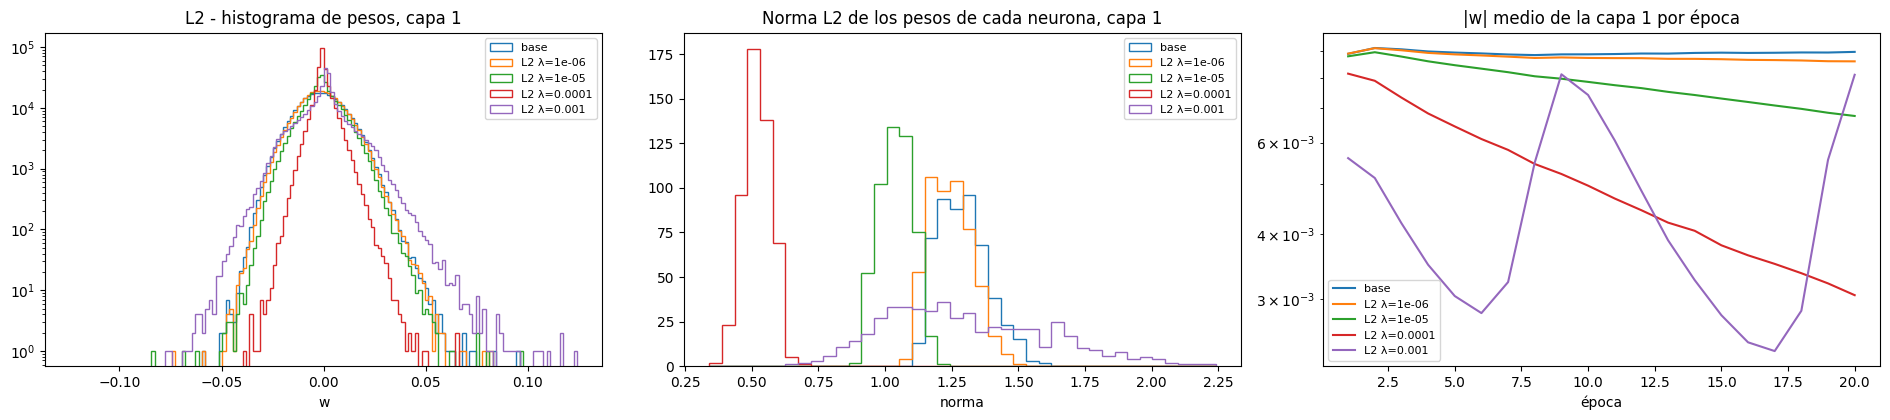

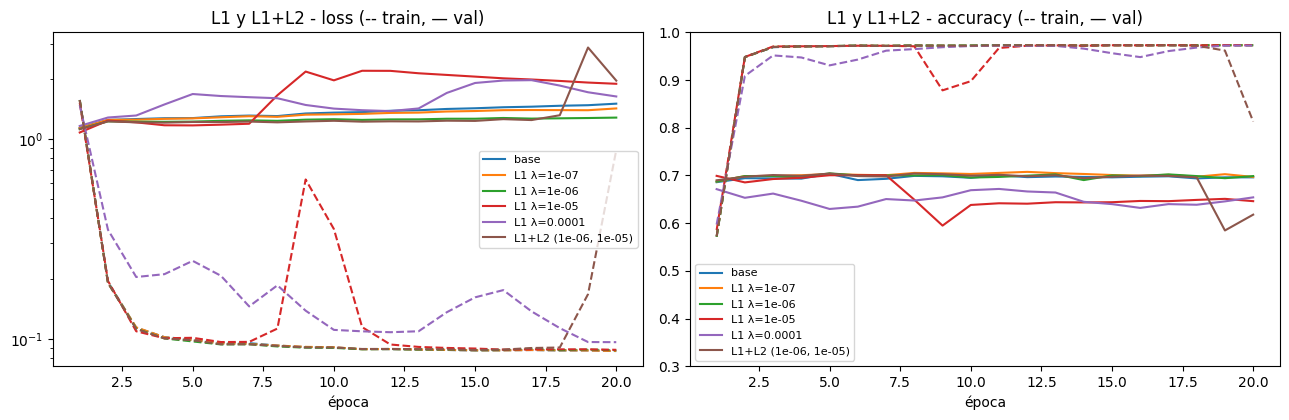

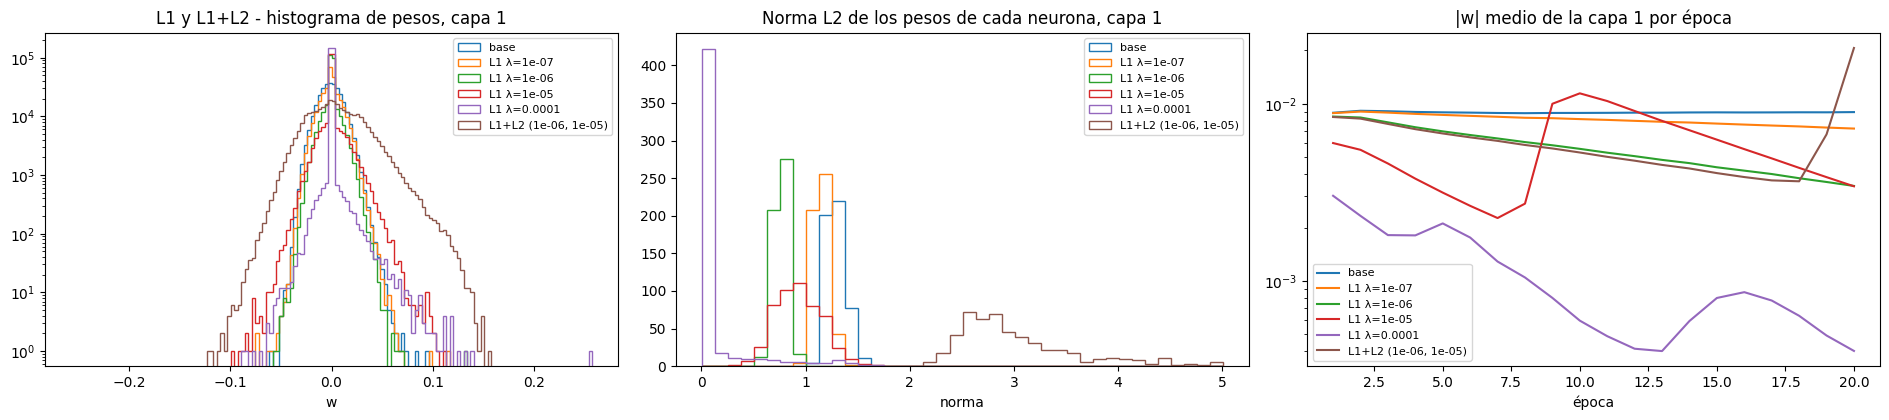

In [9]:
plot_curvas(["base", *grupo_l2], "L2")
plot_pesos(["base", *grupo_l2], "L2")
plot_curvas(["base", *grupo_l1, *grupo_l1l2], "L1 y L1+L2")
plot_pesos(["base", *grupo_l1, *grupo_l1l2], "L1 y L1+L2")

In [10]:
nombres_l1l2 = ["base", *grupo_l2, *grupo_l1, *grupo_l1l2]
display(resumen(nombres_l1l2))
display(resumen_pesos(nombres_l1l2))

,máx val_acc,ép. máx,val_acc final,train_acc final,gap final,val_loss mín,val_loss final,ruido train [pp],ruido val [pp],s/época,ép. conv.
base,0.7035,5,0.6960,0.9732,0.2772,1.138,1.502,1.41,0.18,0.26,2
L2 λ=1e-06,0.7008,5,0.6938,0.9728,0.2791,1.134,1.475,1.42,0.10,0.35,3
L2 λ=1e-05,0.7013,5,0.6911,0.9730,0.2819,1.134,1.396,1.40,0.15,0.35,2
L2 λ=0.0001,0.6982,3,0.6898,0.9729,0.2831,1.122,1.197,1.41,0.28,0.35,2
L2 λ=0.001,0.7084,1,0.5886,0.8980,0.3094,1.053,2.127,2.50,2.16,0.35,1
L1 λ=1e-07,0.7075,12,0.6969,0.9729,0.2761,1.136,1.422,1.41,0.30,0.33,2
L1 λ=1e-06,0.7044,5,0.6986,0.9729,0.2743,1.123,1.279,1.41,0.49,0.33,2
L1 λ=1e-05,0.7004,5,0.6460,0.9732,0.3271,1.078,1.889,1.42,0.20,0.33,1
L1 λ=0.0001,0.6717,11,0.6540,0.9724,0.3184,1.162,1.632,1.69,0.72,0.33,1
"L1+L2 (1e-06, 1e-05)",0.7039,5,0.6178,0.8131,0.1953,1.120,1.959,2.93,1.83,0.43,2


,|w| medio (capa 1),|w| máx (capa 1),norma/neurona (capa 1),% |w|<1e-3 (capa 1),|w| medio (capa 2),|w| máx (capa 2),norma/neurona (capa 2),% |w|<1e-3 (capa 2),|w| medio (salida),|w| máx (salida),norma/neurona (salida),% |w|<1e-3 (salida),n neuronas norma < 0.1 (capa 1)
base,0.0090,0.1333,1.29,7.1,0.0249,0.1492,0.67,2.1,0.0270,0.3631,0.73,1.9,0
L2 λ=1e-06,0.0086,0.1315,1.25,7.6,0.0246,0.1875,0.66,2.2,0.0272,0.2227,0.73,1.9,0
L2 λ=1e-05,0.0067,0.1333,1.04,12.6,0.0229,0.1538,0.62,2.7,0.0274,0.3173,0.75,2.1,0
L2 λ=0.0001,0.0030,0.1015,0.52,29.0,0.0153,0.1379,0.42,6.2,0.0306,0.3767,0.85,2.8,0
L2 λ=0.001,0.0081,0.2000,1.31,13.1,0.0122,0.1496,0.38,9.3,0.0339,0.1701,0.92,4.1,0
L1 λ=1e-07,0.0072,0.1371,1.15,22.3,0.0243,0.1513,0.66,3.4,0.0273,0.3807,0.74,2.5,0
L1 λ=1e-06,0.0034,0.1388,0.77,60.2,0.0216,0.2754,0.61,10.7,0.0288,0.2868,0.80,3.9,0
L1 λ=1e-05,0.0034,0.1777,0.94,73.5,0.0146,0.1983,0.52,37.3,0.0311,0.1820,0.87,7.9,0
L1 λ=0.0001,0.0004,0.2572,0.14,97.4,0.0018,0.4272,0.28,96.1,0.0366,0.2678,1.27,35.4,414
"L1+L2 (1e-06, 1e-05)",0.0206,0.1914,3.02,4.0,0.0300,0.3621,0.85,4.4,0.0312,0.3368,0.89,2.9,0


**Poda.** Como en clase, después de entrenar se ponen en cero los pesos con $\lvert w\rvert$ menor que un umbral y se vuelve a evaluar en validación, con L1 ($\lambda$ = 1e-6) y con la base.

In [11]:
@torch.no_grad()
def podar(name, thr):
    model = models[name]
    originales = [w.clone() for w in kernels(model)]
    for w in kernels(model):
        w[w.abs() < thr] = 0.0
    w1 = kernels(model)[0]
    fila = {"modelo": name, "umbral": thr,
            "% pesos en 0 (capa 1)": 100 * (w1 == 0).float().mean().item(),
            "palabras sin pesos": int((w1.abs().sum(dim=0) == 0).sum().item()),
            "val_acc": evaluate(model, DATA[2], DATA[3])[1]}
    for w, w0 in zip(kernels(model), originales):
        w.copy_(w0)
    return fila


poda = pd.DataFrame([podar(name, thr) for name in ["base", "L1 λ=1e-06"] for thr in [0.0, 1e-3, 3e-3, 1e-2]])
poda.style.format({"umbral": "{:g}", "% pesos en 0 (capa 1)": "{:.1f}", "val_acc": "{:.4f}"}).hide(axis="index")

modelo,umbral,% pesos en 0 (capa 1),palabras sin pesos,val_acc
base,0,0.0,0,0.6960
base,0.001,7.1,0,0.6960
base,0.003,21.2,0,0.6951
base,0.01,63.0,0,0.6995
L1 λ=1e-06,0,0.0,0,0.6986
L1 λ=1e-06,0.001,60.2,0,0.6973
L1 λ=1e-06,0.003,68.7,104,0.6977
L1 λ=1e-06,0.01,86.8,323,0.6942


### Análisis de L2, L1 y L1+L2

**Pesos:**
- **L2 achica los pesos**: el $\lvert w\rvert$ medio de la capa 1 baja de 0.0090 a 0.0086 / 0.0067 / 0.0030 con $\lambda$ = 1e-6 / 1e-5 / 1e-4 (1e-3 es inestable, ver abajo).
- **L1 los lleva a cero**: el 22.3% / 60.2% / 73.5% / 97.4% de los pesos de la capa 1 queda con $\lvert w\rvert < 10^{-3}$ para $\lambda$ = 1e-7 / 1e-6 / 1e-5 / 1e-4 (7.1% en la base). Con 1e-4 apaga 414 de las 512 neuronas y la red pierde capacidad (0.6717).
- **Poda**: con L1 ($\lambda$ = 1e-6) se puede eliminar el 87% de los pesos de la capa 1 y la val acc cambia menos de 0.5 pp (0.6986 → 0.6942).

**Performance.** El máximo de val acc no cambia: queda entre 0.6982 y 0.7084, contra 0.7035 de la base, salvo L1 1e-4. Lo que mejora es la val loss final: de 1.502 a 1.197 con L2 1e-4 y 1.279 con L1 1e-6. La penalización frena el crecimiento de la "seguridad" del modelo, pero la train acc sigue en 0.97: no impide memorizar. En el ejemplo de clase el sobreajuste necesitaba pesos enormes; acá alcanzan pesos chicos, así que achicarlos no le saca esa capacidad a la red.

**Inestabilidad.** L2 1e-3, L1 1e-5 y L1+L2 se desestabilizan: la train loss pega un salto (alrededor de las épocas 9, 9 y 20), la train acc cae y la val acc termina en 0.589, 0.646 y 0.618. En las tres el $\lvert w\rvert$ medio venía bajando y salta junto con la loss (gráfico de $\lvert w\rvert$ por época); L1 1e-4 también oscila. Pasa antes cuanto más fuerte es la penalización, pero también con $\lambda$ chicos (L1+L2): con esta entrada, `lr = 1e-3` está cerca del límite de estabilidad (sección 8).

**Ruido y tiempos.** Mientras el entrenamiento es estable, el ruido de train no cambia (1.40–1.42 pp): la penalización es determinística. El tiempo por época sube de 0.25 s a 0.33–0.35 s con L1 o L2 y a 0.43 s con L1+L2, porque el término recorre los 7.0 M de pesos en cada paso. La convergencia no cambia (1 a 3 épocas).

## 6. Dropout

Se prueban las recomendaciones de clase:

- **Rate** en las capas ocultas de 0.2 y 0.5 (el rango recomendado) y 0.8, cerca del caso extremo del ejemplo de clase (0.75).
- **Dropout también en la entrada** (0.5).
- **Learning rate ×10** (`1e-2`), solo, con **max-norm = 4** y con max-norm + **ReduceLROnPlateau** (`factor = 0.2`, `patience = 2`).

In [12]:
PLATEAU = dict(factor=0.2, patience=2, min_lr=1e-5)
grupo_drop = {
    "drop=0.2": dict(dropout=0.2),
    "drop=0.5": dict(dropout=0.5, eval_train=True),
    "drop=0.8": dict(dropout=0.8, eval_train=True),
    "drop=0.5 + entrada 0.5": dict(dropout=0.5, input_dropout=0.5, eval_train=True),
}
grupo_drop_lr = {
    "drop=0.5 lr=0.01": dict(dropout=0.5, lr=1e-2),
    "drop=0.5 lr=0.01 + max_norm=4": dict(dropout=0.5, lr=1e-2, max_norm=4.0),
    "drop=0.5 lr=0.01 + max_norm=4 + plateau": dict(dropout=0.5, lr=1e-2, max_norm=4.0, plateau=PLATEAU),
}
for name, kw in {**grupo_drop, **grupo_drop_lr}.items():
    run_experiment(name, **kw)

drop=0.2                                   máx val_acc 0.6986 (ép.  6) | final 0.6253 | train 0.9681 | val_loss final 3.951 | 0.27 s/época
drop=0.5                                   máx val_acc 0.6991 (ép.  1) | final 0.6487 | train 0.9550 | val_loss final 3.379 | 0.26 s/época
drop=0.8                                   máx val_acc 0.6933 (ép. 16) | final 0.6902 | train 0.7930 | val_loss final 1.190 | 0.27 s/época
drop=0.5 + entrada 0.5                     máx val_acc 0.6832 (ép. 10) | final 0.6739 | train 0.8811 | val_loss final 1.537 | 0.27 s/época
drop=0.5 lr=0.01                           máx val_acc 0.1569 (ép.  2) | final 0.1065 | train 0.1061 | val_loss final 2.999 | 0.27 s/época
drop=0.5 lr=0.01 + max_norm=4              máx val_acc 0.3893 (ép.  9) | final 0.3389 | train 0.2488 | val_loss final 2.287 | 0.31 s/época
drop=0.5 lr=0.01 + max_norm=4 + plateau    máx val_acc 0.5387 (ép. 19) | final 0.5347 | train 0.5086 | val_loss final 1.626 | 0.31 s/época


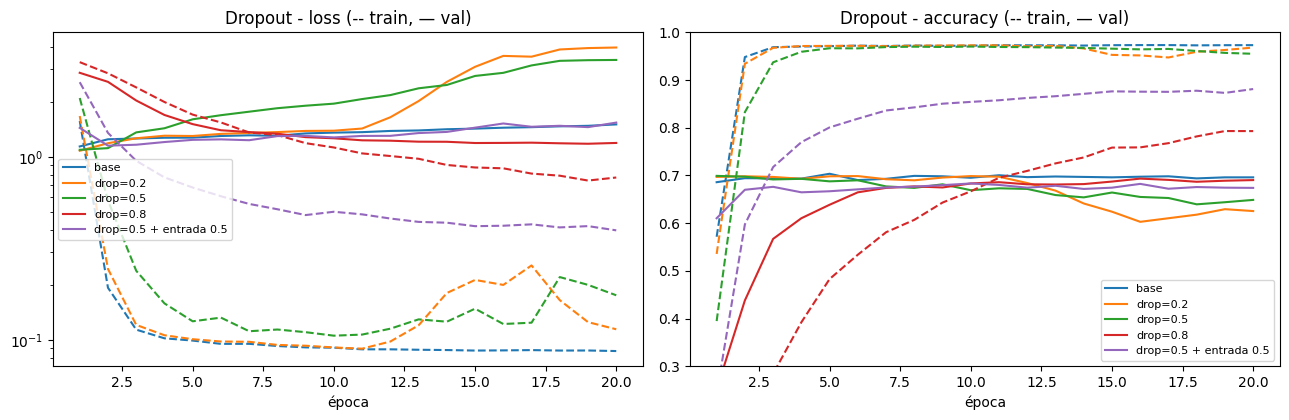

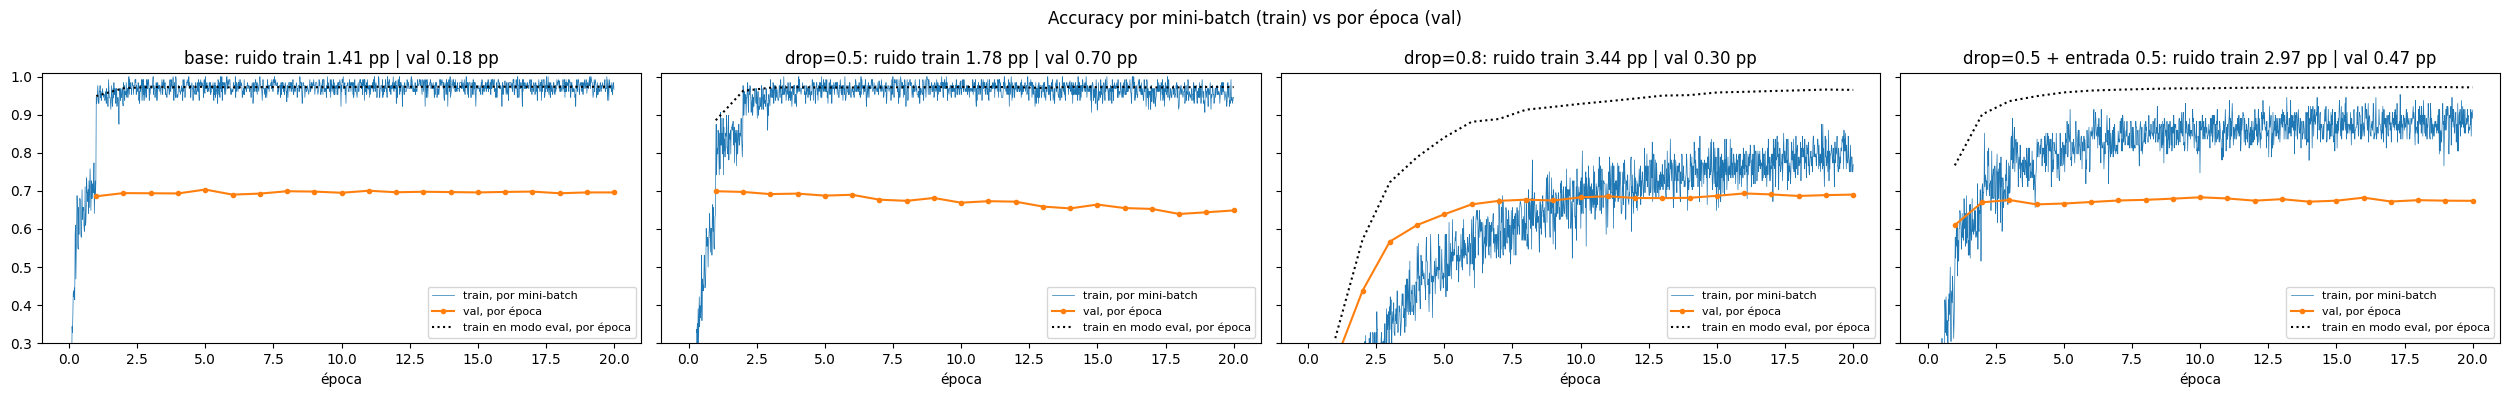

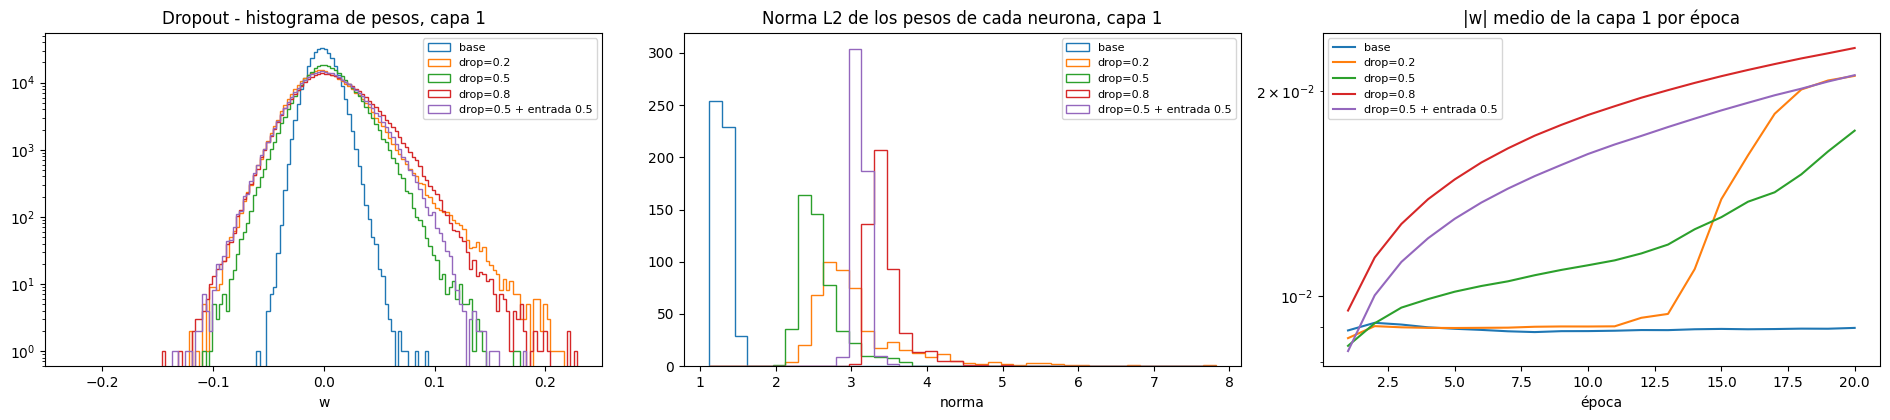

In [13]:
plot_curvas(["base", *grupo_drop], "Dropout")
plot_ruido(["base", "drop=0.5", "drop=0.8", "drop=0.5 + entrada 0.5"], "Accuracy por mini-batch (train) vs por época (val)")
plot_pesos(["base", *grupo_drop], "Dropout")

In [14]:
nombres_drop = ["base", *grupo_drop, *grupo_drop_lr]
display(resumen(nombres_drop))
display(resumen_pesos(nombres_drop))
h = results["drop=0.5 lr=0.01 + max_norm=4 + plateau"]
print("lr por época con ReduceLROnPlateau:", " ".join(f"{v:.0e}" for v in h["lr"]))
print("\nTrain medido durante el entrenamiento vs en modo eval (época 20):")
for name in ["base", "drop=0.5", "drop=0.8", "drop=0.5 + entrada 0.5"]:
    h = results[name]
    print(f"  {name:24s} train_acc {h['train_acc'][-1]:.4f} | train_acc en eval {h['train_acc_eval'][-1]:.4f} "
          f"| val_acc {h['val_acc'][-1]:.4f}")
print("\nPrimeras 6 épocas:")
curvas(["base", "drop=0.5", "drop=0.8", "drop=0.5 + entrada 0.5"], n=6)
print("\nPrimera época en la que train_acc supera a val_acc:",
      {name: int(np.argmax(np.array(results[name]["train_acc"]) > np.array(results[name]["val_acc"]))) + 1
       for name in ["base", *grupo_drop]})

,máx val_acc,ép. máx,val_acc final,train_acc final,gap final,val_loss mín,val_loss final,ruido train [pp],ruido val [pp],s/época,ép. conv.
base,0.7035,5,0.6960,0.9732,0.2772,1.138,1.502,1.41,0.18,0.26,2
drop=0.2,0.6986,6,0.6253,0.9681,0.3428,1.078,3.951,1.78,1.39,0.27,1
drop=0.5,0.6991,1,0.6487,0.9550,0.3063,1.092,3.379,1.78,0.70,0.26,1
drop=0.8,0.6933,16,0.6902,0.7930,0.1027,1.178,1.190,3.44,0.30,0.27,11
drop=0.5 + entrada 0.5,0.6832,10,0.6739,0.8811,0.2072,1.150,1.537,2.97,0.47,0.27,3
drop=0.5 lr=0.01,0.1569,2,0.1065,0.1061,-0.0004,2.684,2.999,2.82,0.30,0.27,1
drop=0.5 lr=0.01 + max_norm=4,0.3893,9,0.3389,0.2488,-0.0901,2.093,2.287,4.21,1.63,0.31,9
drop=0.5 lr=0.01 + max_norm=4 + plateau,0.5387,19,0.5347,0.5086,-0.0261,1.621,1.626,4.31,2.81,0.31,19


,|w| medio (capa 1),|w| máx (capa 1),norma/neurona (capa 1),% |w|<1e-3 (capa 1),|w| medio (capa 2),|w| máx (capa 2),norma/neurona (capa 2),% |w|<1e-3 (capa 2),|w| medio (salida),|w| máx (salida),norma/neurona (salida),% |w|<1e-3 (salida),n neuronas norma < 0.1 (capa 1)
base,0.0090,0.1333,1.29,7.1,0.0249,0.1492,0.67,2.1,0.0270,0.3631,0.73,1.9,0
drop=0.2,0.0211,0.2305,3.10,3.3,0.0368,0.2493,1.03,1.7,0.0352,0.1807,0.97,1.6,0
drop=0.5,0.0175,0.1824,2.59,4.0,0.0350,0.2006,0.98,1.8,0.0371,0.1426,1.01,1.5,0
drop=0.8,0.0232,0.2721,3.45,3.0,0.0342,0.1870,0.96,1.8,0.0237,0.1129,0.66,2.3,0
drop=0.5 + entrada 0.5,0.0211,0.1803,3.11,3.2,0.0341,0.1891,0.96,1.8,0.0308,0.1469,0.85,1.9,0
drop=0.5 lr=0.01,0.1533,1.7934,22.11,0.4,0.0814,1.2049,2.24,0.7,0.0697,0.5729,2.23,1.3,0
drop=0.5 lr=0.01 + max_norm=4,0.0188,0.4037,4.00,14.7,0.0712,0.7005,1.92,0.7,0.0629,0.6808,1.98,1.2,0
drop=0.5 lr=0.01 + max_norm=4 + plateau,0.0248,0.3171,4.00,5.4,0.0685,0.6931,1.84,0.8,0.0604,0.6807,1.87,1.1,0


lr por época con ReduceLROnPlateau: 1e-02 1e-02 1e-02 1e-02 1e-02 1e-02 1e-02 1e-02 1e-02 1e-02 1e-02 1e-02 2e-03 2e-03 2e-03 2e-03 2e-03 2e-03 2e-03 2e-03

Train medido durante el entrenamiento vs en modo eval (época 20):
  base                     train_acc 0.9732 | train_acc en eval 0.9735 | val_acc 0.6960
  drop=0.5                 train_acc 0.9550 | train_acc en eval 0.9725 | val_acc 0.6487
  drop=0.8                 train_acc 0.7930 | train_acc en eval 0.9652 | val_acc 0.6902
  drop=0.5 + entrada 0.5   train_acc 0.8811 | train_acc en eval 0.9718 | val_acc 0.6739

Primeras 6 épocas:
base:
   train      [0.571, 0.948, 0.969, 0.97, 0.971, 0.972]
   train eval [0.949, 0.97, 0.973, 0.972, 0.973, 0.972]
   val        [0.686, 0.694, 0.694, 0.693, 0.703, 0.69]
drop=0.5:
   train      [0.395, 0.833, 0.937, 0.959, 0.967, 0.966]
   train eval [0.885, 0.963, 0.971, 0.972, 0.971, 0.972]
   val        [0.699, 0.697, 0.692, 0.693, 0.688, 0.69]
drop=0.8:
   train      [0.083, 0.169, 0.284, 0.392

### Análisis de dropout

**Performance.** Con `lr = 1e-3` dropout no ayuda: máximo de 0.6986 (0.2), 0.6991 (0.5), 0.6933 (0.8) y 0.6832 (0.5 + entrada), contra 0.7035 de la base. Con 0.2 y 0.5 la val loss se dispara (3.951 y 3.379 al final, contra 1.502). Con 0.8 aprende lento pero estable: máximo en la época 16 y la menor val loss final de la sección (1.190). Con un lr más bajo sí ayuda: con `lr = 3e-4`, dropout 0.5 llega a 0.7123, la mejor prueba manual (sección 8).

**Validación por encima de train.** Con 0.8 la val acc supera a la train acc durante las primeras 10 épocas (0.251 contra 0.083 en la primera). Es lo explicado en clase: `train_acc` se mide con dropout activo, con parte de las neuronas apagadas, y validación con la red completa. El mismo train evaluado en modo eval queda por encima de val (0.313 en la primera época). Dropout no evita la memorización, la demora: en modo eval el train termina entre 0.965 y 0.973.

**Ruido.** El de train sube con el rate: 1.78 pp con 0.2 y 0.5 y 3.44 pp con 0.8 (base 1.41). Es casi todo ruido de muestreo del mini-batch: con la train acc de 0.793 de dropout 0.8, el desvío esperado por muestrear 128 documentos es 3.58 pp. Dropout lo sube porque aleja la train acc de la saturación.

**Pesos.** El $\lvert w\rvert$ medio sube (de 0.0090 a 0.0175–0.0232) y sigue creciendo hasta el final: para clasificar con parte de las neuronas apagadas, la red reparte la información entre todas y necesita redundancia.

**lr ×10, max-norm y plateau.** Con `lr = 1e-2` el entrenamiento diverge (máximo 0.1569, norma por neurona 22.1). Max-norm contiene los pesos (todas las neuronas en 4.00), pero la red casi no aprende (0.389). Con plateau el lr recién baja a 2e-3 en la época 13: el punto de partida es demasiado alto. Con Adam el paso por peso es ≈ `lr`: con 13148 entradas, un paso puede mover el vector de pesos de una neurona del orden de $10^{-2}\sqrt{13148} \approx 1.1$, comparable a su norma (1.29 en la base). La receta "×10" es para SGD, y con esta entrada el lr estable ya es bajo.

**Tiempos.** Dropout necesita más épocas: con 0.8 converge en 11, contra 2 de la base. El tiempo por época casi no cambia (0.26–0.27 s contra 0.25 s); max-norm agrega algo (0.31 s) porque reescala los pesos en cada paso.

## 7. Batch Normalization

- **BN** con la arquitectura recomendada: `Linear(bias=False) → BN → relu` en las dos capas ocultas.
- **Momentum**: el default de PyTorch (0.1) contra `0.01`.
- **BN + dropout 0.5**, para verificar la recomendación de no combinarlos.

In [15]:
grupo_bn = {
    "BN": dict(batchnorm=True, eval_train=True),
    "BN mom=0.01": dict(batchnorm=True, bn_momentum=0.01),
    "BN + drop=0.5": dict(batchnorm=True, dropout=0.5),
}
for name, kw in grupo_bn.items():
    run_experiment(name, **kw)

BN                                         máx val_acc 0.6889 (ép.  1) | final 0.6779 | train 0.9729 | val_loss final 1.354 | 0.28 s/época
BN mom=0.01                                máx val_acc 0.6885 (ép.  1) | final 0.6787 | train 0.9729 | val_loss final 1.356 | 0.27 s/época
BN + drop=0.5                              máx val_acc 0.7101 (ép.  2) | final 0.6708 | train 0.9725 | val_loss final 1.438 | 0.29 s/época


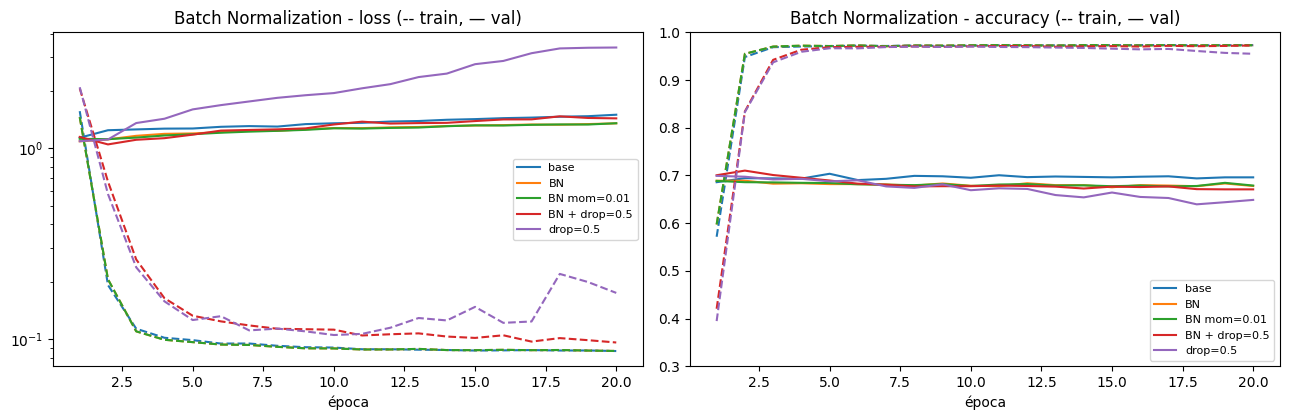

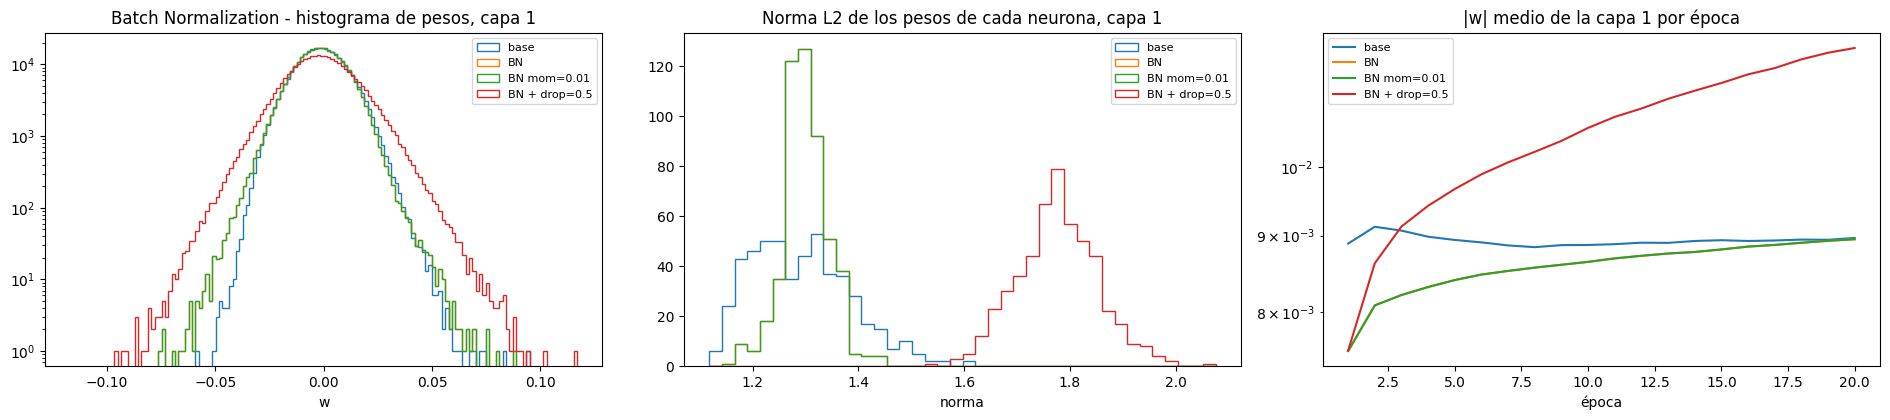

,máx val_acc,ép. máx,val_acc final,train_acc final,gap final,val_loss mín,val_loss final,ruido train [pp],ruido val [pp],s/época,ép. conv.
base,0.7035,5,0.6960,0.9732,0.2772,1.138,1.502,1.41,0.18,0.26,2
BN,0.6889,1,0.6779,0.9729,0.2951,1.090,1.354,1.42,0.36,0.28,1
BN mom=0.01,0.6885,1,0.6787,0.9729,0.2942,1.119,1.356,1.42,0.25,0.27,1
BN + drop=0.5,0.7101,2,0.6708,0.9725,0.3017,1.050,1.438,1.53,0.21,0.29,1
drop=0.5,0.6991,1,0.6487,0.9550,0.3063,1.092,3.379,1.78,0.70,0.26,1


,|w| medio (capa 1),|w| máx (capa 1),norma/neurona (capa 1),% |w|<1e-3 (capa 1),|w| medio (capa 2),|w| máx (capa 2),norma/neurona (capa 2),% |w|<1e-3 (capa 2),|w| medio (salida),|w| máx (salida),norma/neurona (salida),% |w|<1e-3 (salida),n neuronas norma < 0.1 (capa 1),gamma medio (BN)
base,0.0090,0.1333,1.29,7.1,0.0249,0.1492,0.67,2.1,0.0270,0.3631,0.73,1.9,0,-
BN,0.0089,0.1050,1.30,7.2,0.0236,0.0988,0.64,2.3,0.0389,0.1171,1.03,1.3,0,1.04
BN mom=0.01,0.0089,0.1050,1.30,7.2,0.0236,0.0988,0.64,2.3,0.0389,0.1171,1.03,1.3,0,1.04
BN + drop=0.5,0.0120,0.1300,1.78,5.6,0.0266,0.1426,0.74,2.3,0.0470,0.1580,1.25,1.1,0,1.07
drop=0.5,0.0175,0.1824,2.59,4.0,0.0350,0.2006,0.98,1.8,0.0371,0.1426,1.01,1.5,0,-


Primeras 5 épocas:
base:
   train      [0.571, 0.948, 0.969, 0.97, 0.971]
   train eval [0.949, 0.97, 0.973, 0.972, 0.973]
   val        [0.686, 0.694, 0.694, 0.693, 0.703]
BN:
   train      [0.597, 0.955, 0.97, 0.972, 0.971]
   train eval [0.957, 0.972, 0.973, 0.973, 0.972]
   val        [0.689, 0.689, 0.683, 0.684, 0.682]
BN mom=0.01:
   train      [0.597, 0.955, 0.97, 0.972, 0.971]
   val        [0.688, 0.686, 0.685, 0.684, 0.684]


In [16]:
plot_curvas(["base", *grupo_bn, "drop=0.5"], "Batch Normalization")
plot_pesos(["base", *grupo_bn], "Batch Normalization")
nombres_bn = ["base", *grupo_bn, "drop=0.5"]
display(resumen(nombres_bn))
display(resumen_pesos(nombres_bn))
print("Primeras 5 épocas:")
curvas(["base", "BN", "BN mom=0.01"], n=5)

### Análisis de Batch Normalization

**No acelera el arranque.** La val acc de la primera época es 0.689 con BN y 0.686 sin BN. BN normaliza la salida de cada capa, y la estandarización ya hace eso en la entrada; en una red de 2 capas no queda mucho por emparejar.

**No regulariza.** Máximo de 0.6889, contra 0.7035 de la base (−1.5 pp). Mejora un poco la val loss (mínima 1.090 contra 1.138, final 1.354 contra 1.502), y la train acc llega igual a 0.973. Coincide con lo dicho en clase: BN es una técnica de aceleración, y la regularización "de regalo" viene del ruido de estimar $\mu$ y $\sigma$ en cada batch, que con batches de 128 es chico.

**Momentum.** Con `momentum = 0.01` el resultado es prácticamente igual desde la primera época (0.688 contra 0.689). El promedio exponencial que BN usa en inferencia arranca en 0 y 1, y con la entrada estandarizada las activaciones ya están cerca de esos valores, así que su arranque lento no se nota.

**BN + dropout.** Máximo de 0.7101 en la época 2, pero cae a 0.6708 al final: combinarlos no da una mejora sostenida.

**Pesos.** Parecidos a los de la base ($\lvert w\rvert$ medio de 0.0089 contra 0.0090). Con BN su tamaño deja de medir cuán seguro está el modelo: la salida del `Linear` se normaliza, así que escalar los pesos de una neurona no cambia nada. Por eso en la sección 8 el $\lvert w\rvert$ medio de BN crece 14 veces entre `lr = 3e-4` y `1e-2` y la red sigue entrenando.

**Tiempos y ruido.** 0.27 s por época contra 0.25 s, y el mismo ruido de train (1.42 pp).

## 8. Learning rate

 Se barre el lr de Adam en $\{3\cdot10^{-4}, 10^{-3}, 3\cdot10^{-3}, 10^{-2}\}$ para la base, dropout 0.5 y BN, con 12 épocas (para `1e-3` se reutilizan las corridas anteriores).

In [17]:
LRS, EPOCHS_LR = [3e-4, 1e-3, 3e-3, 1e-2], 12
tecnicas = {"base": {}, "drop=0.5": dict(dropout=0.5), "BN": dict(batchnorm=True)}
for tec, kw in tecnicas.items():
    for lr in LRS:
        name = f"{tec} lr={lr:g}"
        if lr == 1e-3:
            results[name] = results[tec]
        elif name not in results:
            run_experiment(name, lr=lr, epochs=EPOCHS_LR, **kw)

base lr=0.0003                             máx val_acc 0.7057 (ép.  8) | final 0.7000 | train 0.9713 | val_loss final 1.181 | 0.25 s/época
base lr=0.003                              máx val_acc 0.6823 (ép.  1) | final 0.6089 | train 0.9402 | val_loss final 6.149 | 0.25 s/época
base lr=0.01                               máx val_acc 0.4980 (ép.  8) | final 0.4755 | train 0.7440 | val_loss final 4.588 | 0.25 s/época
drop=0.5 lr=0.0003                         máx val_acc 0.7123 (ép.  3) | final 0.7008 | train 0.9718 | val_loss final 1.234 | 0.28 s/época
drop=0.5 lr=0.003                          máx val_acc 0.6699 (ép.  2) | final 0.6438 | train 0.9123 | val_loss final 3.793 | 0.26 s/época
BN lr=0.0003                               máx val_acc 0.6947 (ép.  2) | final 0.6752 | train 0.9716 | val_loss final 1.201 | 0.27 s/época
BN lr=0.003                                máx val_acc 0.6774 (ép.  1) | final 0.6584 | train 0.9730 | val_loss final 1.521 | 0.29 s/época
BN lr=0.01                 

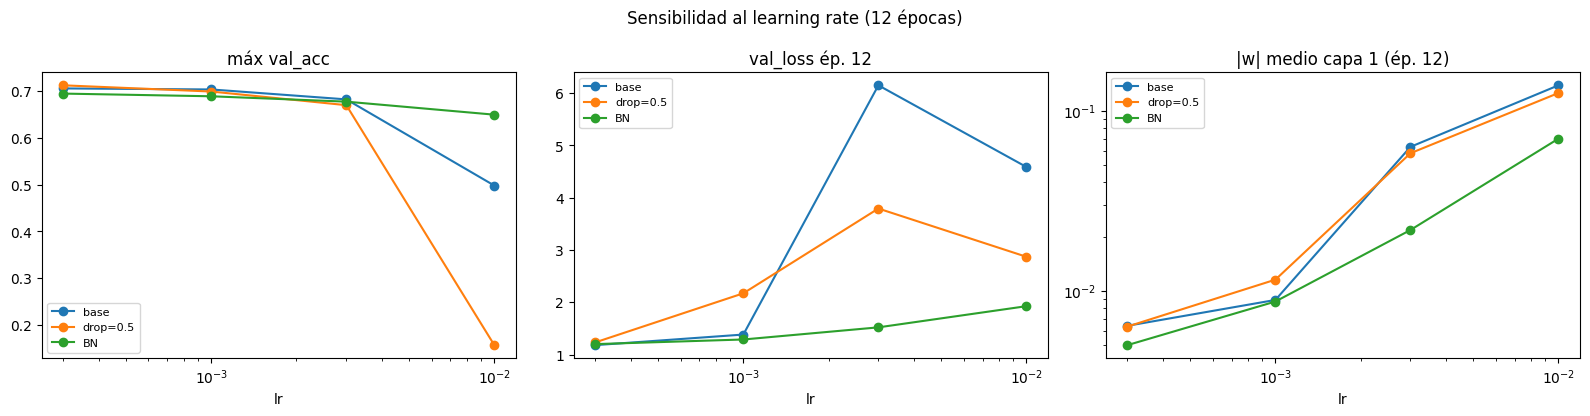

técnica,lr,máx val_acc,ép. máx,val_loss ép. 12,|w| medio capa 1 (ép. 12),ruido val [pp]
base,0.0003,0.7057,8,1.181,0.0064,0.30
base,0.001,0.7035,5,1.384,0.0089,0.51
base,0.003,0.6823,1,6.149,0.0631,1.52
base,0.01,0.4980,8,4.588,0.1387,1.82
drop=0.5,0.0003,0.7123,3,1.234,0.0063,0.15
drop=0.5,0.001,0.6991,1,2.172,0.0115,0.62
drop=0.5,0.003,0.6699,2,3.793,0.0582,0.69
drop=0.5,0.01,0.1569,2,2.871,0.1257,0.72
BN,0.0003,0.6947,2,1.201,0.0050,0.32
BN,0.001,0.6889,1,1.289,0.0087,0.28


In [18]:
rows = []
for tec in tecnicas:
    for lr in LRS:
        h = results[f"{tec} lr={lr:g}"]
        va, vl = np.array(h["val_acc"][:EPOCHS_LR]), np.array(h["val_loss"][:EPOCHS_LR])
        rows.append({"técnica": tec, "lr": lr, "máx val_acc": va.max(), "ép. máx": va.argmax() + 1,
                     "val_loss ép. 12": vl[-1], "|w| medio capa 1 (ép. 12)": h["w_abs"][EPOCHS_LR - 1],
                     "ruido val [pp]": 100 * np.mean(np.abs(np.diff(va[-8:])))})
df_lr = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for i, tec in enumerate(tecnicas):
    d = df_lr[df_lr["técnica"] == tec]
    for a, col in zip(ax, ["máx val_acc", "val_loss ép. 12", "|w| medio capa 1 (ép. 12)"]):
        a.plot(d["lr"], d[col], "o-", color=f"C{i}", label=tec)
        a.set(xscale="log", xlabel="lr", title=col)
ax[2].set_yscale("log")
for a in ax:
    a.legend(fontsize=8)
plt.suptitle("Sensibilidad al learning rate (12 épocas)"); plt.tight_layout(); plt.show()

df_lr.style.format({"lr": "{:g}", "máx val_acc": "{:.4f}",
                    "val_loss ép. 12": "{:.3f}", "|w| medio capa 1 (ép. 12)": "{:.4f}", "ruido val [pp]": "{:.2f}"}).hide(axis="index")

### Análisis del learning rate

- **El lr estable es bajo.** En la base, el máximo de val acc es 0.7057 con 3e-4 y 0.7035 con 1e-3, pero cae a 0.6823 con 3e-3 y a 0.4980 con 1e-2. Con entradas estandarizadas que llegan a decenas, un mismo paso en los pesos cambia mucho más la salida de la primera capa.
- **Dropout es la más sensible.** Su mejor resultado es con el lr más bajo (0.7123 con 3e-4, la mejor prueba manual) y con 1e-2 diverge.
- **BN es la más robusta.** Entre 3e-4 y 1e-2 pierde 4.5 pp (0.6947 → 0.6496), contra 20.8 pp de la base: al normalizar las activaciones de cada capa, la escala del gradiente queda pareja. Aun así, su mejor valor también es con el lr más bajo.
- **Pesos y ruido.** El $\lvert w\rvert$ medio de la capa 1 crece con el lr (en la base, de 0.0064 a 0.1387 en la época 12) y con él la val loss (de 1.181 a 4.588, con un pico de 6.149 en 3e-3). El ruido de val también crece en la base (0.30 → 1.82 pp); con BN queda entre 0.23 y 0.45 pp.

## 9. Búsqueda de hiperparámetros con Optuna

Se amplía la búsqueda del TP anterior con las tres técnicas. Se fija lo que ese TP ya resolvió: el preprocesamiento (sección 1) y el optimizador (Adam).

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Arquitectura | `n_layers` | 1, 2, 3 |
| | `n_units_l{i}` | 128, 256, 512 |
| | `activation` | relu, tanh |
| Entrenamiento | `batch_size` | 64, 128, 256 |
| | `lr` (Adam) | 1e-4 – 1e-2 (log) |
| **Penalización de pesos** | `weight_reg` | `none`, `l1`, `l2`, `l1_l2` |
| | `l1` (si aplica) | 1e-8 – 1e-3 (log) |
| | `l2` (si aplica) | 1e-7 – 1e-3 (log) |
| **Regularización por capa** | `layer_reg` | `none`, `dropout`, `batchnorm` |
| Dropout | `dropout` (capas ocultas) | 0.1 – 0.8 |
| | `input_dropout` (entrada) | 0.0 – 0.6 |
| | `max_norm` | sin restricción, 3, 4, 5 |

- **Dropout y BN son excluyentes** (`layer_reg`). L1/L2 se puede combinar con cualquiera.
- Los $\lambda$ van en escala logarítmica hasta 1e-3, para que el óptimo no quede en el borde del rango.
- Con BN se usa `Linear(bias=False) → BN → activación` y el momentum default.

**Presupuesto**: 200 trials de hasta 30 épocas con early stopping (paciencia 5). Los primeros 20 son aleatorios y el resto los propone TPE. El `objective` devuelve la mejor val acc.

**Pruning**: `PercentilePruner(75)`. Después de 10 trials completos y 5 épocas de *warmup*, corta los trials que están en el 25% inferior. Es menos agresivo que el `MedianPruner` del TP anterior, para no descartar dropout, que converge más lento (sección 6).

In [19]:
N_TRIALS, MAX_EPOCHS, PATIENCE = 200, 30, 5


def suggest_config(trial):
    n_layers = trial.suggest_int("n_layers", 1, 3)
    cfg = dict(
        hidden=[trial.suggest_categorical(f"n_units_l{i}", [128, 256, 512]) for i in range(n_layers)],
        activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
        batch_size=trial.suggest_categorical("batch_size", [64, 128, 256]),
        lr=trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        epochs=MAX_EPOCHS,
    )
    weight_reg = trial.suggest_categorical("weight_reg", ["none", "l1", "l2", "l1_l2"])
    if weight_reg in ("l1", "l1_l2"):
        cfg["l1"] = trial.suggest_float("l1", 1e-8, 1e-3, log=True)
    if weight_reg in ("l2", "l1_l2"):
        cfg["l2"] = trial.suggest_float("l2", 1e-7, 1e-3, log=True)
    layer_reg = trial.suggest_categorical("layer_reg", ["none", "dropout", "batchnorm"])
    if layer_reg == "dropout":
        cfg["dropout"] = trial.suggest_float("dropout", 0.1, 0.8)
        cfg["input_dropout"] = trial.suggest_float("input_dropout", 0.0, 0.6)
        cfg["max_norm"] = trial.suggest_categorical("max_norm", [0, 3, 4, 5])   # 0 = sin restricción
    elif layer_reg == "batchnorm":
        cfg["batchnorm"] = True
    return cfg


def objective(trial):
    cfg = suggest_config(trial)
    torch.manual_seed(SEED + trial.number)
    model = build_model(cfg)
    optimizer = optim.Adam(model.parameters(), lr=cfg["lr"])
    with mlflow.start_run(run_name=f"trial_{trial.number}"):
        mlflow.log_params(trial.params)
        h = train_model(model, DATA, optimizer, cfg, trial=trial, patience=PATIENCE)
        train_time = sum(h["epoch_time"])
        mlflow.log_metrics({"train_time_s": train_time, "best_val_acc": h["best_val_acc"], "best_epoch": h["best_epoch"]})
        mlflow.set_tag("state", "pruned" if h["pruned"] else "complete")
    for k, v in dict(cfg=cfg, train_time_s=train_time, epochs_run=len(h["val_acc"]), best_epoch=h["best_epoch"],
                     best_val_acc=h["best_val_acc"], val_loss_min=min(h["val_loss"]), n_params=count_params(model),
                     w_abs=weight_stats(model)["|w| medio (capa 1)"]).items():
        trial.set_user_attr(k, v)
    if h["pruned"]:
        raise optuna.TrialPruned()
    return h["best_val_acc"]


def log_trial(study, trial):
    # Solo se imprimen los trials que mejoran el mejor resultado (todos quedan registrados en MLflow)
    if trial.state != optuna.trial.TrialState.COMPLETE or study.best_trial.number != trial.number:
        return
    ua, p = trial.user_attrs, trial.params
    reg = [p["weight_reg"], p["layer_reg"]]
    print(f"trial {trial.number:3d} {trial.state.name:8s} val_acc={ua.get('best_val_acc', 0):.4f} "
          f"épocas={ua.get('epochs_run'):2d} t={ua.get('train_time_s', 0):5.1f}s  L={p['n_layers']} {p['activation']:4s} "
          f"lr={p['lr']:.1e}  {' + '.join(reg)}")


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=20),
    pruner=optuna.pruners.PercentilePruner(75.0, n_startup_trials=10, n_warmup_steps=5),   # solo corta el 25% inferior
)
t_search = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, callbacks=[log_trial])
t_search = time.perf_counter() - t_search

print(f"\nTiempo total de búsqueda: {t_search/60:.1f} min")
print("Mejores hiperparámetros:", study.best_params)
print(f"Mejor val acc: {study.best_value:.4f} (época {study.best_trial.user_attrs['best_epoch']})")

trial   0 COMPLETE val_acc=0.6650 épocas= 7 t=  0.8s  L=2 relu lr=4.6e-03  l1_l2 + dropout
trial   1 COMPLETE val_acc=0.6792 épocas= 8 t=  1.9s  L=2 relu lr=1.8e-04  l2 + batchnorm
trial   2 COMPLETE val_acc=0.6801 épocas= 8 t=  3.0s  L=1 relu lr=1.2e-04  l1_l2 + batchnorm
trial   3 COMPLETE val_acc=0.6902 épocas= 9 t=  0.9s  L=1 tanh lr=1.4e-04  l2 + batchnorm
trial   6 COMPLETE val_acc=0.6955 épocas=13 t=  3.8s  L=1 tanh lr=2.5e-03  l1 + none
trial   8 COMPLETE val_acc=0.7053 épocas=12 t=  2.4s  L=1 relu lr=2.2e-04  l2 + dropout
trial  10 COMPLETE val_acc=0.7282 épocas=16 t=  6.0s  L=1 relu lr=3.4e-04  l1 + none
trial  26 COMPLETE val_acc=0.7366 épocas=15 t=  3.4s  L=2 relu lr=1.1e-04  l1 + dropout
trial  52 COMPLETE val_acc=0.7446 épocas=10 t=  2.5s  L=1 relu lr=1.4e-04  l1_l2 + none

Tiempo total de búsqueda: 9.6 min
Mejores hiperparámetros: {'n_layers': 1, 'n_units_l0': 256, 'activation': 'relu', 'batch_size': 128, 'lr': 0.00013843986206746344, 'weight_reg': 'l1_l2', 'l1': 0.00039

**Explicación del código.** El espacio es condicional: `l1` y `l2` solo existen si `weight_reg` los incluye, y `dropout`, `input_dropout` y `max_norm` solo si `layer_reg = dropout`. Cada trial guarda su configuración y resultados en `user_attrs` y en MLflow; por pantalla se imprimen solo los que mejoran el mejor resultado.

### 9.1 Análisis de la búsqueda

In [20]:
rows = []
for t in study.trials:
    if t.state not in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED):
        continue
    p, ua = t.params, t.user_attrs
    rows.append(dict(
        number=t.number, state="podado" if t.state == optuna.trial.TrialState.PRUNED else "completo",
        val_acc=ua["best_val_acc"], val_loss_min=ua["val_loss_min"], best_epoch=ua["best_epoch"], epochs_run=ua["epochs_run"],
        weight_reg=p["weight_reg"], l1=p.get("l1"), l2=p.get("l2"), layer_reg=p["layer_reg"], dropout=p.get("dropout"),
        input_dropout=p.get("input_dropout"), max_norm=p.get("max_norm"), n_layers=p["n_layers"],
        units="-".join(str(p[f"n_units_l{i}"]) for i in range(p["n_layers"])), activation=p["activation"],
        batch_size=p["batch_size"], lr=p["lr"], w_abs=ua["w_abs"], train_time_s=ua["train_time_s"],
        s_per_epoch=ua["train_time_s"] / ua["epochs_run"],
    ))
df = pd.DataFrame(rows)
print(df["state"].value_counts().to_string())
(df.sort_values("val_acc", ascending=False).head(12)
   .style.format({"val_acc": "{:.4f}", "val_loss_min": "{:.3f}", "l1": "{:.1e}", "l2": "{:.1e}", "dropout": "{:.2f}",
                  "input_dropout": "{:.2f}", "max_norm": "{:.0f}", "lr": "{:.1e}", "w_abs": "{:.4f}",
                  "train_time_s": "{:.1f}", "s_per_epoch": "{:.2f}"}, na_rep="-").hide(axis="index"))

state
completo    127
podado       73


number,state,val_acc,val_loss_min,best_epoch,epochs_run,weight_reg,l1,l2,layer_reg,dropout,input_dropout,max_norm,n_layers,units,activation,batch_size,lr,w_abs,train_time_s,s_per_epoch
52,completo,0.7446,1.091,5,10,l1_l2,3.9e-04,8.1e-07,none,-,-,-,1,256,relu,128,1.4e-04,0.0007,2.5,0.25
107,completo,0.7441,1.046,4,9,l1,4.4e-04,-,none,-,-,-,1,128,relu,64,1.4e-04,0.0010,2.8,0.31
196,completo,0.7441,1.033,8,13,l1_l2,2.1e-04,1.9e-07,dropout,0.62,0.05,0,1,512,relu,128,1.6e-04,0.0008,5.4,0.42
147,completo,0.7437,1.024,3,8,l1_l2,1.9e-04,2.9e-04,dropout,0.18,0.04,0,1,256,relu,128,2.2e-04,0.0011,2.0,0.24
76,completo,0.7437,1.201,14,19,l1_l2,6.8e-04,4.4e-06,none,-,-,-,1,128,relu,256,1.2e-04,0.0007,2.1,0.11
193,completo,0.7437,1.084,10,15,l1_l2,3.1e-04,1.2e-07,dropout,0.59,0.11,0,1,512,relu,128,1.1e-04,0.0006,6.2,0.41
145,completo,0.7433,1.129,8,13,l1_l2,3.3e-04,3.0e-04,none,-,-,-,1,256,relu,256,1.4e-04,0.0007,1.7,0.13
198,completo,0.7433,1.029,7,12,l1_l2,1.7e-04,1.2e-07,dropout,0.58,0.05,0,1,512,relu,128,1.4e-04,0.0008,5.0,0.42
192,completo,0.7433,1.102,9,14,l1_l2,3.5e-04,1.3e-07,dropout,0.59,0.02,0,1,512,relu,128,1.1e-04,0.0005,5.9,0.42
65,completo,0.7428,1.054,6,11,l1,5.6e-04,-,none,-,-,-,1,128,relu,64,1.4e-04,0.0009,3.5,0.32


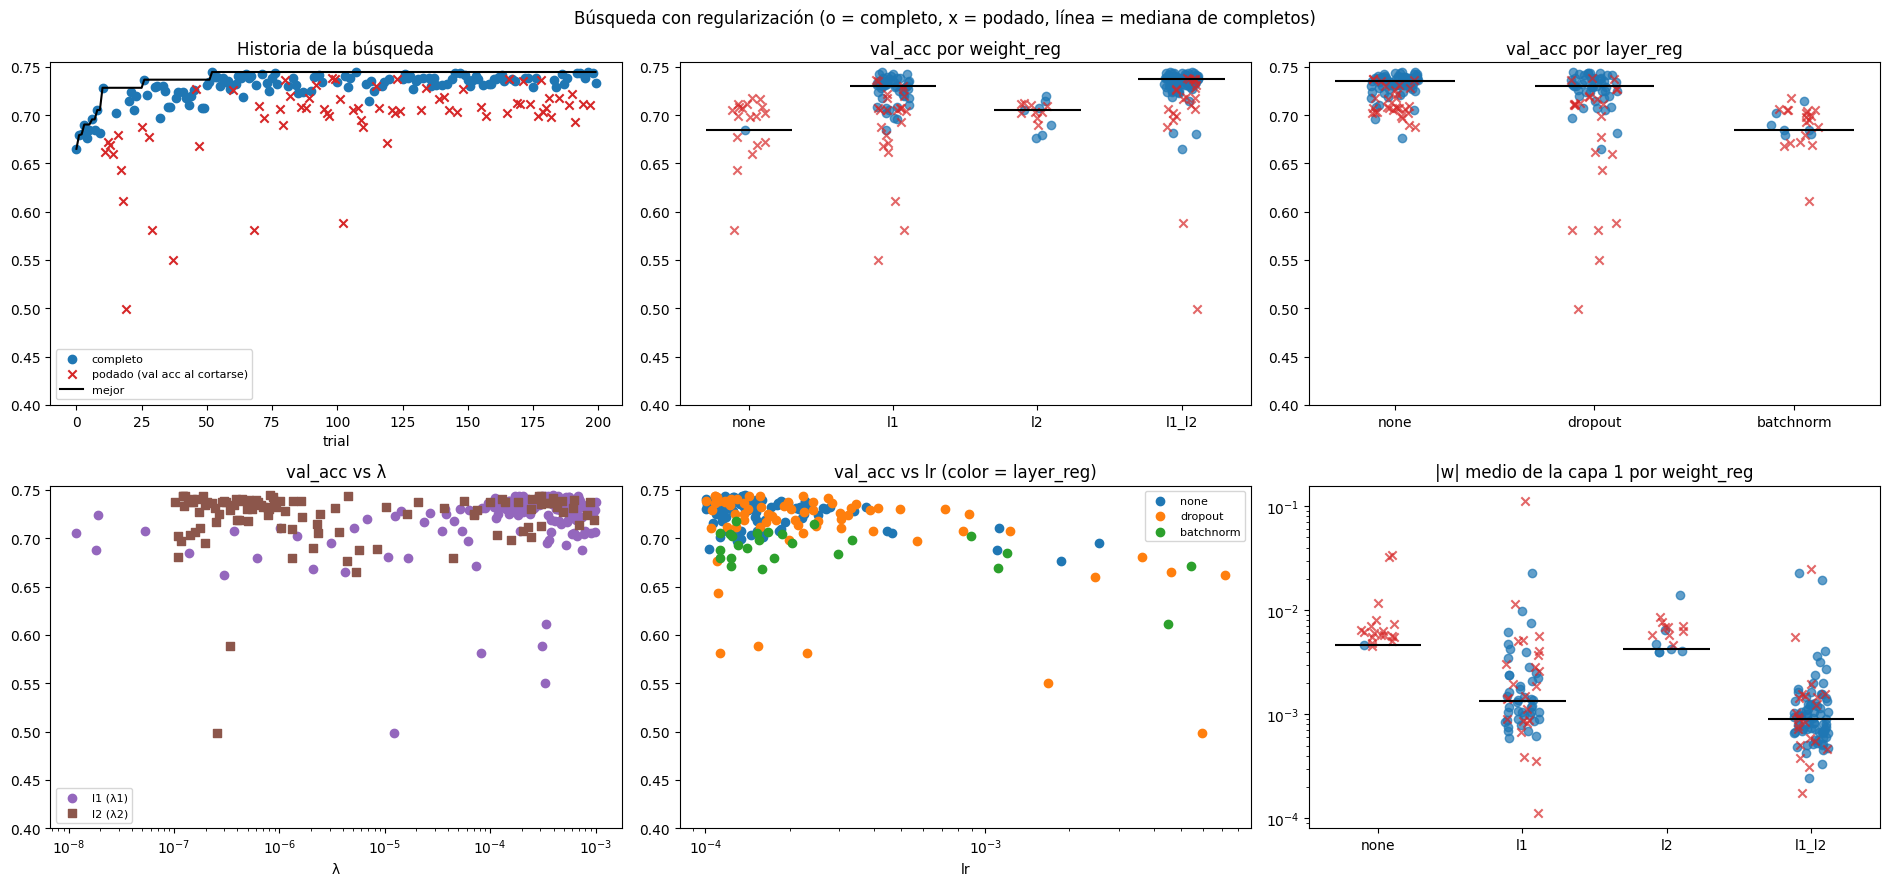

In [21]:
def strip_plot(ax, col, y="val_acc", order=None):
    cats = order or sorted(df[col].unique())
    for i, c in enumerate(cats):
        for st, mk, color in [("completo", "o", "C0"), ("podado", "x", "C3")]:
            v = df.loc[(df[col] == c) & (df["state"] == st), y]
            ax.scatter(np.full(len(v), i) + np.random.uniform(-0.12, 0.12, len(v)), v, marker=mk, color=color, alpha=0.7)
        vc = df.loc[(df[col] == c) & (df["state"] == "completo"), y]
        if len(vc):
            ax.hlines(vc.median(), i - 0.3, i + 0.3, color="k")
    ax.set_xticks(range(len(cats)), [str(c) for c in cats])
    ax.set_title(f"{y} por {col}")


ORD_W, ORD_L = ["none", "l1", "l2", "l1_l2"], ["none", "dropout", "batchnorm"]
COL_L = {"none": "C0", "dropout": "C1", "batchnorm": "C2"}
ylim = (max(0.4, df["val_acc"].min() - 0.02), df["val_acc"].max() + 0.01)
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
axes = axes.ravel()
comp, pod = df[df.state == "completo"], df[df.state == "podado"]
axes[0].scatter(comp["number"], comp["val_acc"], label="completo")
axes[0].scatter(pod["number"], pod["val_acc"], marker="x", color="C3", label="podado (val acc al cortarse)")
axes[0].plot(df["number"], df["val_acc"].where(df.state == "completo").cummax().ffill(), color="k", label="mejor")
axes[0].set(title="Historia de la búsqueda", xlabel="trial"); axes[0].legend(fontsize=8)
strip_plot(axes[1], "weight_reg", order=ORD_W)
strip_plot(axes[2], "layer_reg", order=ORD_L)
axes[3].scatter(df["l1"], df["val_acc"], color="C4", label="l1 (λ1)")
axes[3].scatter(df["l2"], df["val_acc"], color="C5", marker="s", label="l2 (λ2)")
axes[3].set(xscale="log", title="val_acc vs λ", xlabel="λ"); axes[3].legend(fontsize=8)
for lreg in ORD_L:
    d = df[df.layer_reg == lreg]
    axes[4].scatter(d["lr"], d["val_acc"], color=COL_L[lreg], label=lreg)
axes[4].set(xscale="log", title="val_acc vs lr (color = layer_reg)", xlabel="lr"); axes[4].legend(fontsize=8)
for a in axes[:5]:
    a.set_ylim(*ylim)
strip_plot(axes[5], "weight_reg", y="w_abs", order=ORD_W)
axes[5].set(yscale="log", title="|w| medio de la capa 1 por weight_reg")
plt.suptitle("Búsqueda con regularización (o = completo, x = podado, línea = mediana de completos)")
plt.tight_layout(); plt.show()

In [22]:
def resumen_hp(col):
    g = df.groupby(col)
    return pd.DataFrame({
        "trials": g.size(),
        "% podados": g["state"].apply(lambda s: 100 * (s == "podado").mean()),
        "mediana val_acc (completos)": g.apply(lambda d: d.loc[d.state == "completo", "val_acc"].median(), include_groups=False),
        "máx val_acc": g["val_acc"].max(),
        "mín val_loss": g["val_loss_min"].min(),
        "mejor época (mediana, completos)": g.apply(lambda d: d.loc[d.state == "completo", "best_epoch"].median(), include_groups=False),
        "s/época (mediana)": g["s_per_epoch"].median(),
        "|w| medio capa 1 (mediana)": g["w_abs"].median(),
    }).round(4)


for col in ["weight_reg", "layer_reg", "n_layers"]:
    print(resumen_hp(col).to_string(), "\n")

importances = optuna.importance.get_param_importances(study)
print("Importancia (PED-ANOVA):", {k: round(v, 3) for k, v in importances.items()})
pod = df[df.state == "podado"]
print(f"Podados: {len(pod)} de {len(df)} | época de corte: {pod['epochs_run'].value_counts().sort_index().to_dict()}")

            trials  % podados  mediana val_acc (completos)  máx val_acc  mín val_loss  mejor época (mediana, completos)  s/época (mediana)  |w| medio capa 1 (mediana)
weight_reg                                                                                                                                                            
l1              68    35.2941                       0.7300       0.7441        0.9557                               4.0             0.3104                      0.0014
l1_l2           97    22.6804                       0.7371       0.7446        0.9782                               4.0             0.2639                      0.0009
l2              16    56.2500                       0.7053       0.7194        0.9825                               4.0             0.2126                      0.0061
none            19    94.7368                       0.6840       0.7181        1.0350                               2.0             0.1728                      0.006

### Análisis de la búsqueda

**Mejor configuración** (trial 52): 1 capa oculta de 256, `relu`, `batch_size = 128`, `lr ≈ 1.4e-4`, L1 con $\lambda_1 \approx$ 3.9e-4 (y L2 casi nulo, 8.1e-7), sin dropout ni BN → **val acc = 0.7446** en la época 5.

**L1 es lo que más aporta.** Los 12 mejores trials usan L1, con $\lambda_1$ entre 1.7e-4 y 6.8e-4, una sola capa y lr entre 1.1e-4 y 2.2e-4. El máximo sin L1 es 0.7194: **L1 suma unos 2.5 pp**. La comparación es desigual: TPE concentró la búsqueda en L1 (165 de 200 trials), y de los 19 trials sin penalización solo 1 llegó a completarse. Los pesos lo reflejan: la mediana del $\lvert w\rvert$ medio de la capa 1 es 0.0014 con L1, contra 0.0060 sin penalización. Con la entrada estandarizada, L1 hace selección de features y compensa la amplificación de las palabras raras. Son $\lambda_1$ más altos que el máximo de las pruebas manuales (1e-4), que ahí apagaba 414 neuronas: esas corridas eran de 20 épocas con `lr = 1e-3`, y estas llegan a su máximo entre las épocas 3 y 14 con `lr` ≈ 1.4e-4.

**Dropout y BN.** Dropout no suma sobre L1: el mejor trial con dropout llega a 0.7441, igual que sin él, y los que están entre los 12 mejores tienen dropout en la entrada casi nulo (0.02 a 0.11). BN queda abajo (máximo 0.7176), como en la sección 7.

**Arquitectura.** Como en el TP anterior, 1 capa es lo mejor (0.7446, contra 0.7366 con 2 y 0.7176 con 3).

**Importancia de hiperparámetros.** PED-ANOVA da 0.417 para `lr`, consistente con la sección 8. Le siguen `input_dropout` (0.321) y `l1` (0.150); la de `input_dropout` hay que tomarla con cuidado, porque ese parámetro solo existe en los trials con dropout.

**Tiempos y pruning.** La búsqueda tardó 9.3 min. Se podaron 73 de 200 trials, la mayoría en la época 6 (la primera después del *warmup*). Como el pruner compara contra los trials completos, que son los mejores, corta más del 25%, sobre todo a los que ya van peor (el 94.7% de los trials sin penalización).

**Comparación con el TP anterior.** El mejor MLP del TP anterior llegaba a 0.7636 de val acc. Acá el mejor llega a 0.7446 (−1.9 pp), en línea con los 2.1 pp que cuesta estandarizar (sección 4).

## 10. Entrenamiento final y evaluación en test

Se entrena la mejor configuración con **todo** el train (el TF-IDF y el escalador se reajustan con los 11314 documentos), durante las épocas en las que el mejor trial alcanzó su máximo, y se evalúa en test. Como referencia se usa el mejor MLP del TP anterior (sin regularización, TF-IDF sin estandarizar).

In [23]:
best_cfg = dict(study.best_trial.user_attrs["cfg"], epochs=max(study.best_trial.user_attrs["best_epoch"], 1), eval_train=True)
_, X_train_final, X_test_final = featurize(train_texts, test_texts, MIN_DF)   # TF-IDF + escalador ajustados con todo el train
DATA_FINAL = (*to_device(X_train_final, newsgroups_train.target), *to_device(X_test_final, newsgroups_test.target))

torch.manual_seed(SEED)
model = build_model(best_cfg, input_dim=X_train_final.shape[1])
optimizer = optim.Adam(model.parameters(), lr=best_cfg["lr"])
with mlflow.start_run(run_name="mlp_reg_final"):
    mlflow.log_params({k: str(v) for k, v in best_cfg.items()})
    history = train_model(model, DATA_FINAL, optimizer, best_cfg, verbose=True, run_name="final")
    test_loss, test_accuracy = evaluate(model, DATA_FINAL[2], DATA_FINAL[3])
    mlflow.log_metrics({"train_time_s": sum(history["epoch_time"]), "test_acc": test_accuracy})

# Referencia: mejor MLP del TP anterior (sin regularización), mismo split
MLP_PREV_VAL, MLP_PREV_TEST = 0.7636, 0.6950
print(f"\nConfiguración: {best_cfg}")
print(f"Parámetros: {count_params(model):,} | épocas: {best_cfg['epochs']} | tiempo: {sum(history['epoch_time']):.1f} s")
print(f"MLP regularizado          -> val (búsqueda) {study.best_value:.4f} | test {test_accuracy:.4f} | test loss {test_loss:.3f}")
print(f"MLP sin regularizar (TP anterior) -> val (búsqueda) {MLP_PREV_VAL:.4f} | test {MLP_PREV_TEST:.4f}")
print(f"Train acc final: durante el entrenamiento {history['train_acc'][-1]:.4f} | en modo eval {history['train_acc_eval'][-1]:.4f}")
print("Pesos:", {k: round(v, 4) for k, v in weight_stats(model).items() if "capa 1" in k})

[final] Epoch 1/5 - train_loss: 2.5206 train_acc: 0.5042 - val_loss: 2.1455 val_acc: 0.6430 - lr: 1.4e-04 (0.4 s)
[final] Epoch 2/5 - train_loss: 1.6129 train_acc: 0.8576 - val_loss: 1.7359 val_acc: 0.6741 - lr: 1.4e-04 (0.3 s)
[final] Epoch 3/5 - train_loss: 1.1753 train_acc: 0.8850 - val_loss: 1.5069 val_acc: 0.6834 - lr: 1.4e-04 (0.3 s)
[final] Epoch 4/5 - train_loss: 0.9106 train_acc: 0.9004 - val_loss: 1.3905 val_acc: 0.6816 - lr: 1.4e-04 (0.3 s)
[final] Epoch 5/5 - train_loss: 0.7450 train_acc: 0.9148 - val_loss: 1.3208 val_acc: 0.6810 - lr: 1.4e-04 (0.3 s)

Configuración: {'hidden': [256], 'activation': 'relu', 'batch_size': 128, 'lr': 0.00013843986206746344, 'epochs': 5, 'l1': 0.0003941861453698199, 'l2': 8.125825317896416e-07, 'eval_train': True}
Parámetros: 3,886,356 | épocas: 5 | tiempo: 1.7 s
MLP regularizado          -> val (búsqueda) 0.7446 | test 0.6810 | test loss 1.321
MLP sin regularizar (TP anterior) -> val (búsqueda) 0.7636 | test 0.6950
Train acc final: durante el 

En el log de arriba, las columnas `val_*` están calculadas sobre **test**, solo como referencia.

### Resultado final

| | MLP sin regularizar (TP anterior) | MLP regularizado |
|---|---|---|
| Entrada | TF-IDF (norma L2 por documento), `min_df = 2` | TF-IDF estandarizado por palabra, `min_df = 5` |
| Modelo | 1 capa de 128, `tanh`, RMSprop | 1 capa de 256, `relu`, Adam |
| Regularización | — | L1 $\lambda_1 \approx$ 3.9e-4 + L2 $\lambda_2 \approx$ 8.1e-7 |
| Parámetros | 2.56 M | 3.89 M |
| Épocas | 9 | 5 |
| Val acc (búsqueda) | 0.7636 | 0.7446 |
| Test acc | **0.6950** | 0.6810 |

- **Test −1.4 pp.** Es el costo del cambio de entrada (−2.1 pp con la red base, sección 4), que la regularización compensa solo en parte.
- **El modelo es esparso**: el 85.4% de los pesos de la primera capa tiene $\lvert w\rvert < 10^{-3}$, por L1.
- **No llegó a memorizar**: la train acc en modo eval es 0.945, por debajo del 0.973 de las redes sin regularizar.
- Los dos modelos pierden 6 a 7 pp entre validación y test, por el split *bydate* (el test son posts posteriores), algo que la regularización no corrige.

## 11. Conclusiones

- **Estandarización.** Es la recomendación de clase, pero en texto amplifica las palabras raras, desalinea train y validación y baja el lr estable: cuesta 2.1 pp con la red base. Se usó `min_df = 5` para acotar ese efecto.
- **L1 / L2.** Hacen con los pesos lo que dice la teoría: L2 los achica y L1 los lleva a cero (se puede podar el 87% de la capa 1 sin cambiar el resultado). En la red 2×512 no mueven el máximo de val acc, pero frenan el crecimiento de la val loss. En la búsqueda, **L1 es lo que más aporta** (≈ +2.5 pp).
- **Dropout.** Con `lr = 1e-3` no ayuda; con `lr = 3e-4` da la mejor prueba manual. Demora la memorización, al principio deja validación por encima de train, sube el ruido de train y necesita más épocas. En la búsqueda no suma sobre L1.
- **Batch Normalization.** Con la entrada ya estandarizada no acelera ni regulariza, pero es la técnica más robusta al learning rate.
- **Learning rate.** Es el hiperparámetro más importante. Con esta entrada el rango estable es bajo, así que la receta de subirlo con dropout no se puede aplicar.
- **Pesos y ruido.** A la red le alcanzan pesos chicos para memorizar; L1 y L2 los bajan y dropout los sube. El ruido de train es casi todo de muestreo del mini-batch.
- **Resultado.** El mejor modelo (1 capa de 256 con L1) llega a 0.6810 en test, por debajo del 0.6950 del TP anterior: la regularización recupera parte del costo de estandarizar, no todo. Las pruebas manuales son con una sola semilla, así que diferencias menores a ≈ 0.5 pp no son concluyentes.

## Uso de IA

Se usó Claude como asistente para adaptar el código. Y a ayudar a mejorar la redaccion de las secciones y conclusiones, pero siempre basado en mis propias palabras
